# Prepared by:


Sara Alharbi

Lena Alenezi

Yazeed Alshurify

Jawaher




In [ ]:
!pip install roboflow

In [ ]:
!pip install ultralytics==8.0.20

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.2/261.2 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 277.3/277.3 kB 13.2 MB/s eta 0:00:00
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (23.7 MB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (823 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (14.1 MB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl (731.7 MB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl (410.6 MB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl (121.6 MB)
  Using cached nvidia_curand_cu12-10.3.2.106-py3-none-manylinux1_x86_64.whl (56.5 MB)
  Using cached nvidia_cusolver_cu12-11.4.5.107-py3-none-manylinux1_x86_64.whl (124.2 MB)
  Using cached nvidia_cusparse_cu12-12.1.0.106-py3-none-manylinux1_x86_64.whl (196.0 MB)
  Using cached nvidia_nccl_cu12-2.19.3-py3-none-many

In [ ]:
pip install supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 1.4 MB/s eta 0:00:00


In [ ]:
#imports
import os
import glob
import random
import supervision as sv
import ultralytics
import json

from roboflow import Roboflow
from IPython import display
from ultralytics import YOLO
from IPython.display import display, Image
import matplotlib.pyplot as plt


#Downloud dataset

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="2liz2aWMzz6wkQNAm0z4")
project = rf.workspace("prasku-mxsdv").project("blimp_yolo_v8_custom")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...
Dependency ultralytics==8.0.196 is required but found version=8.0.20, to fix: `pip install ultralytics==8.0.196`



Extracting Dataset Version Zip to Blimp_Yolo_v8_Custom-1 in yolov8:: 100%|██████████| 13950/13950 [00:02<00:00, 6614.06it/s]


#Train pre-trained model

In [ ]:
!yolo detect train model=yolov8l.pt data=/content/Blimp_Yolo_v8_Custom-1/data.yaml workers=2 batch=12 device=0 epochs=20 patience=10 name=yolov8_balloon_default

100% 83.7M/83.7M [00:00<00:00, 226MB/s]

Ultralytics YOLOv8.0.20 🚀 Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
yolo/engine/trainer: task=detect, mode=train, model=yolov8l.yaml, data=/content/Blimp_Yolo_v8_Custom-1/data.yaml, epochs=20, patience=10, batch=12, imgsz=640, save=True, cache=False, device=0, workers=2, project=None, name=yolov8_balloon_default, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, image_weights=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, overlap_mask=True, mask_ratio=4, dropout=False, val=True, save_json=False, save_hybrid=False, conf=0.001, iou=0.7, max_det=300, half=False, dnn=False, plots=False, source=ultralytics/assets/, show=False, save_txt=False, save_conf=False, save_crop=False, hide_labels=False, hide_conf=False, vid_stride=1, line_thickness=3, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, boxes=True, format=torchscript

**We got 0.82 mAP Before tuning** ;|

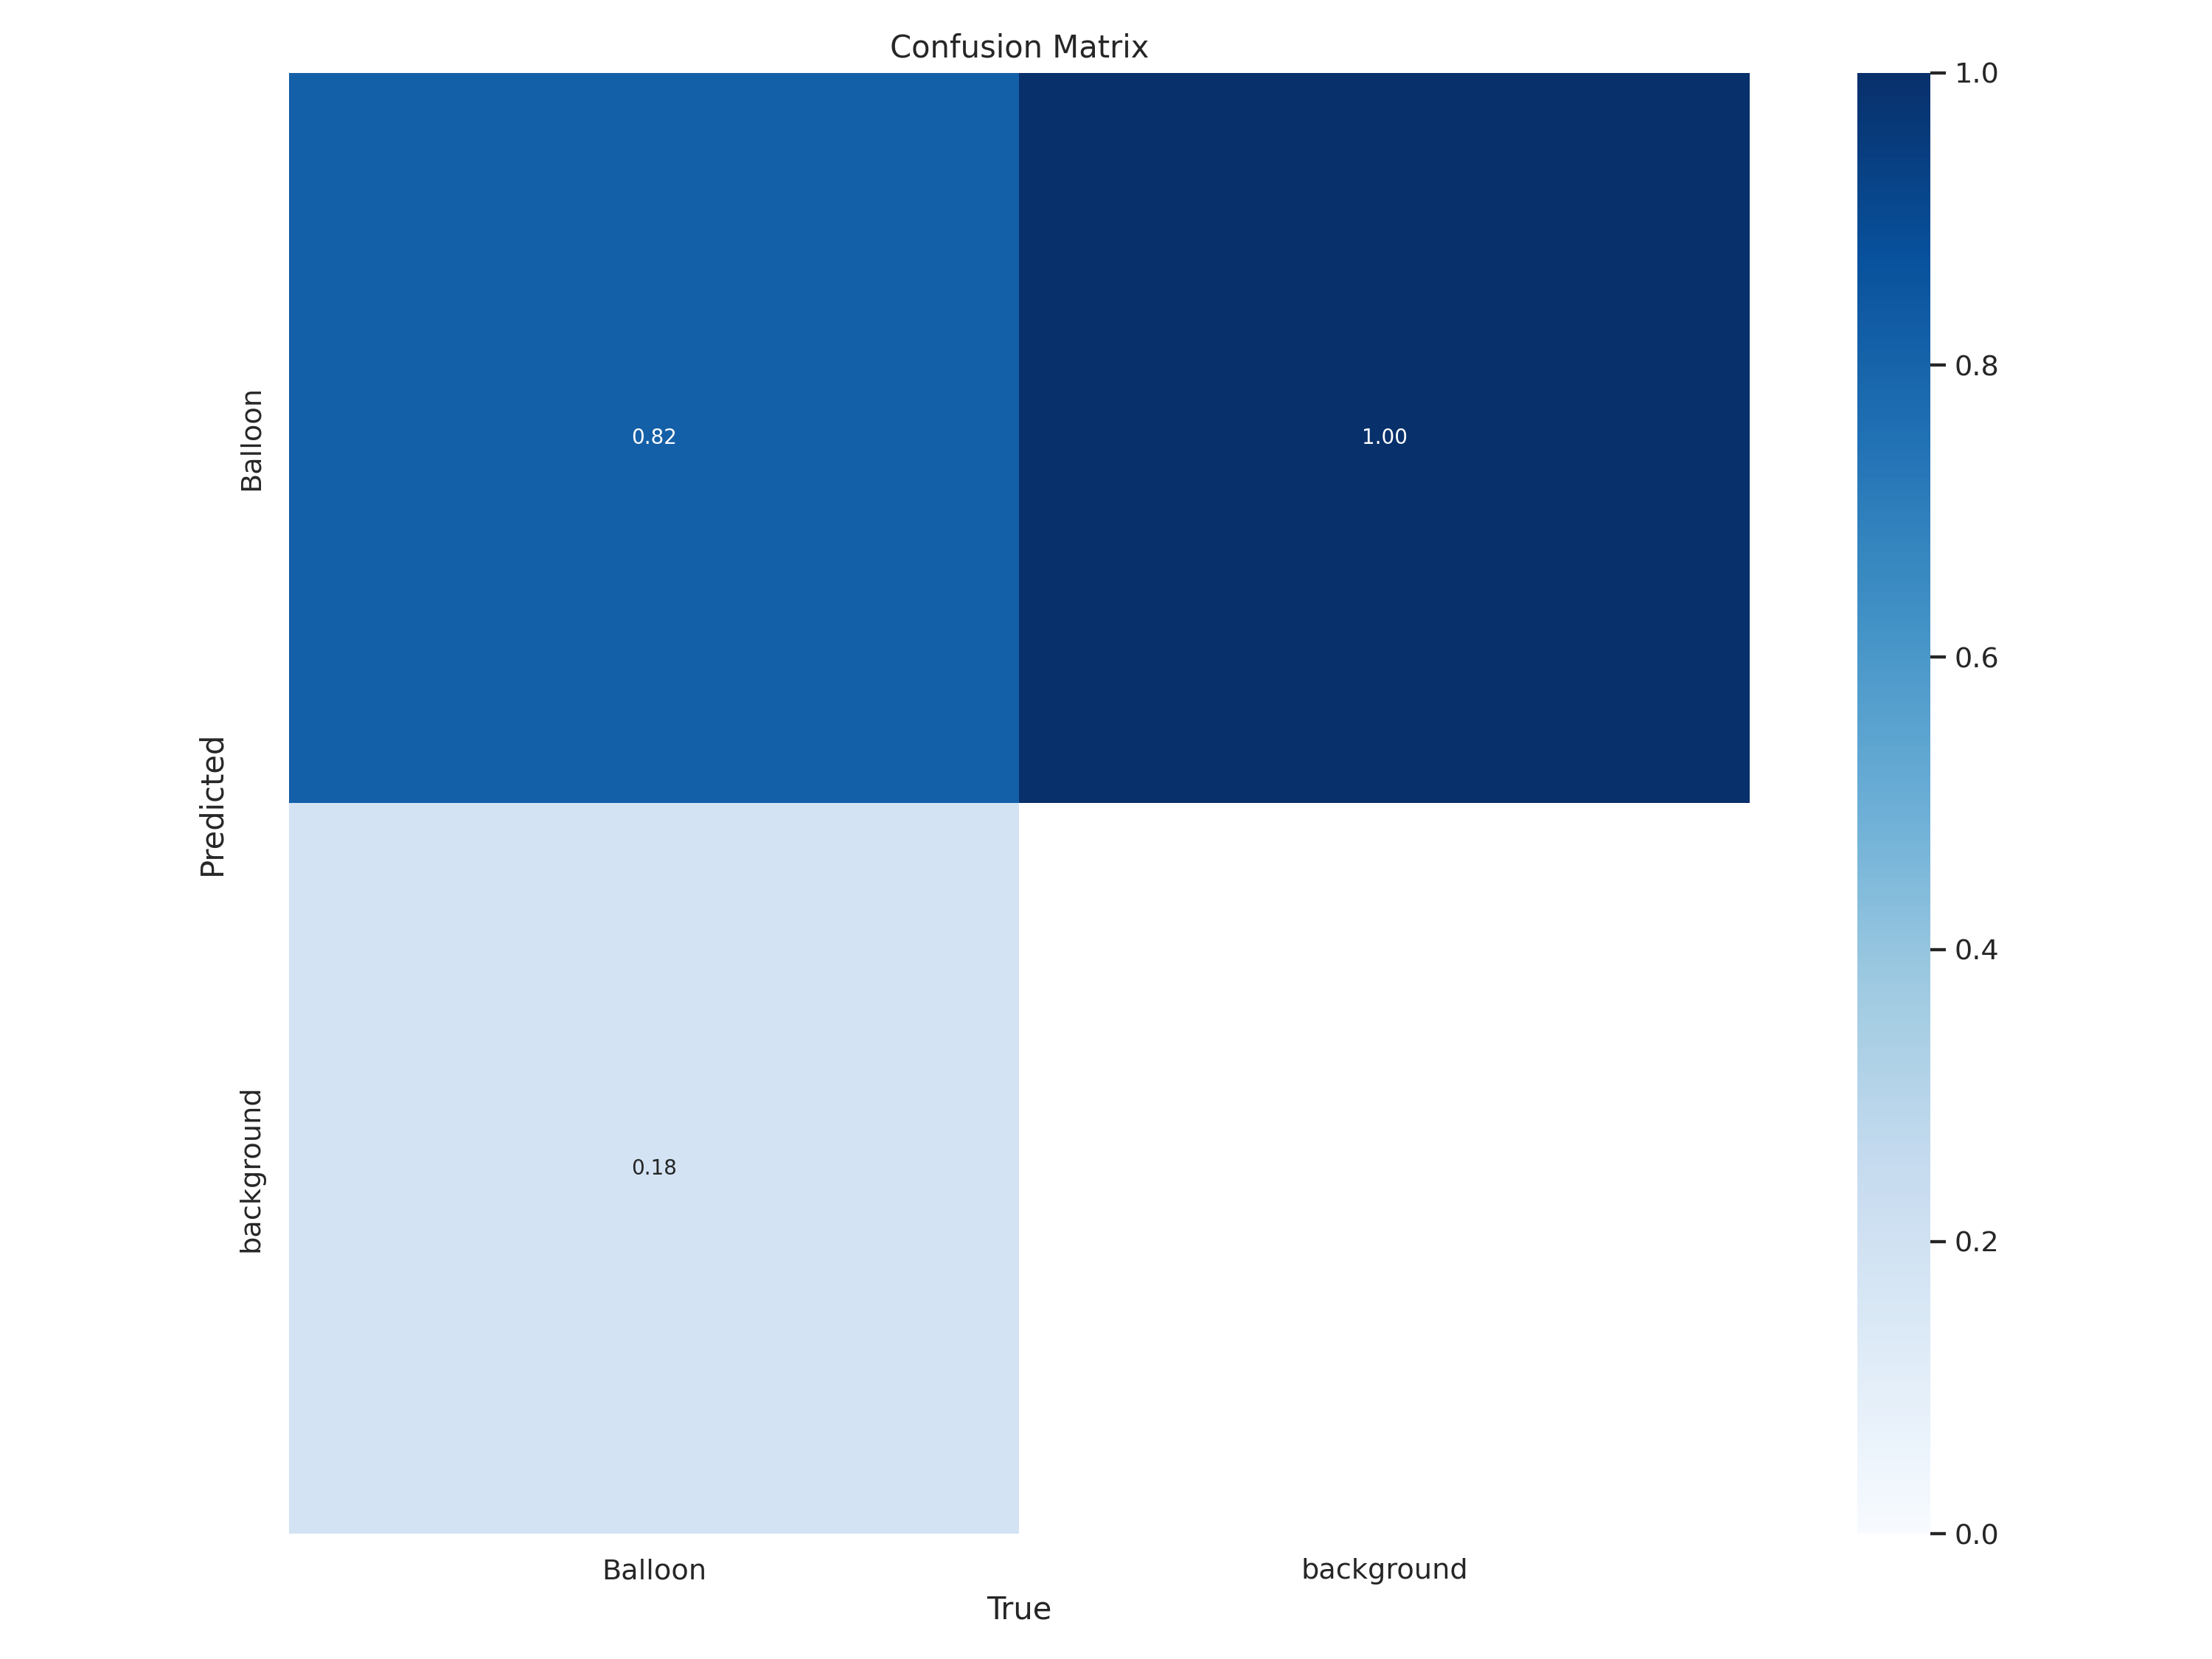

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_balloon_default/confusion_matrix.png', width=800)

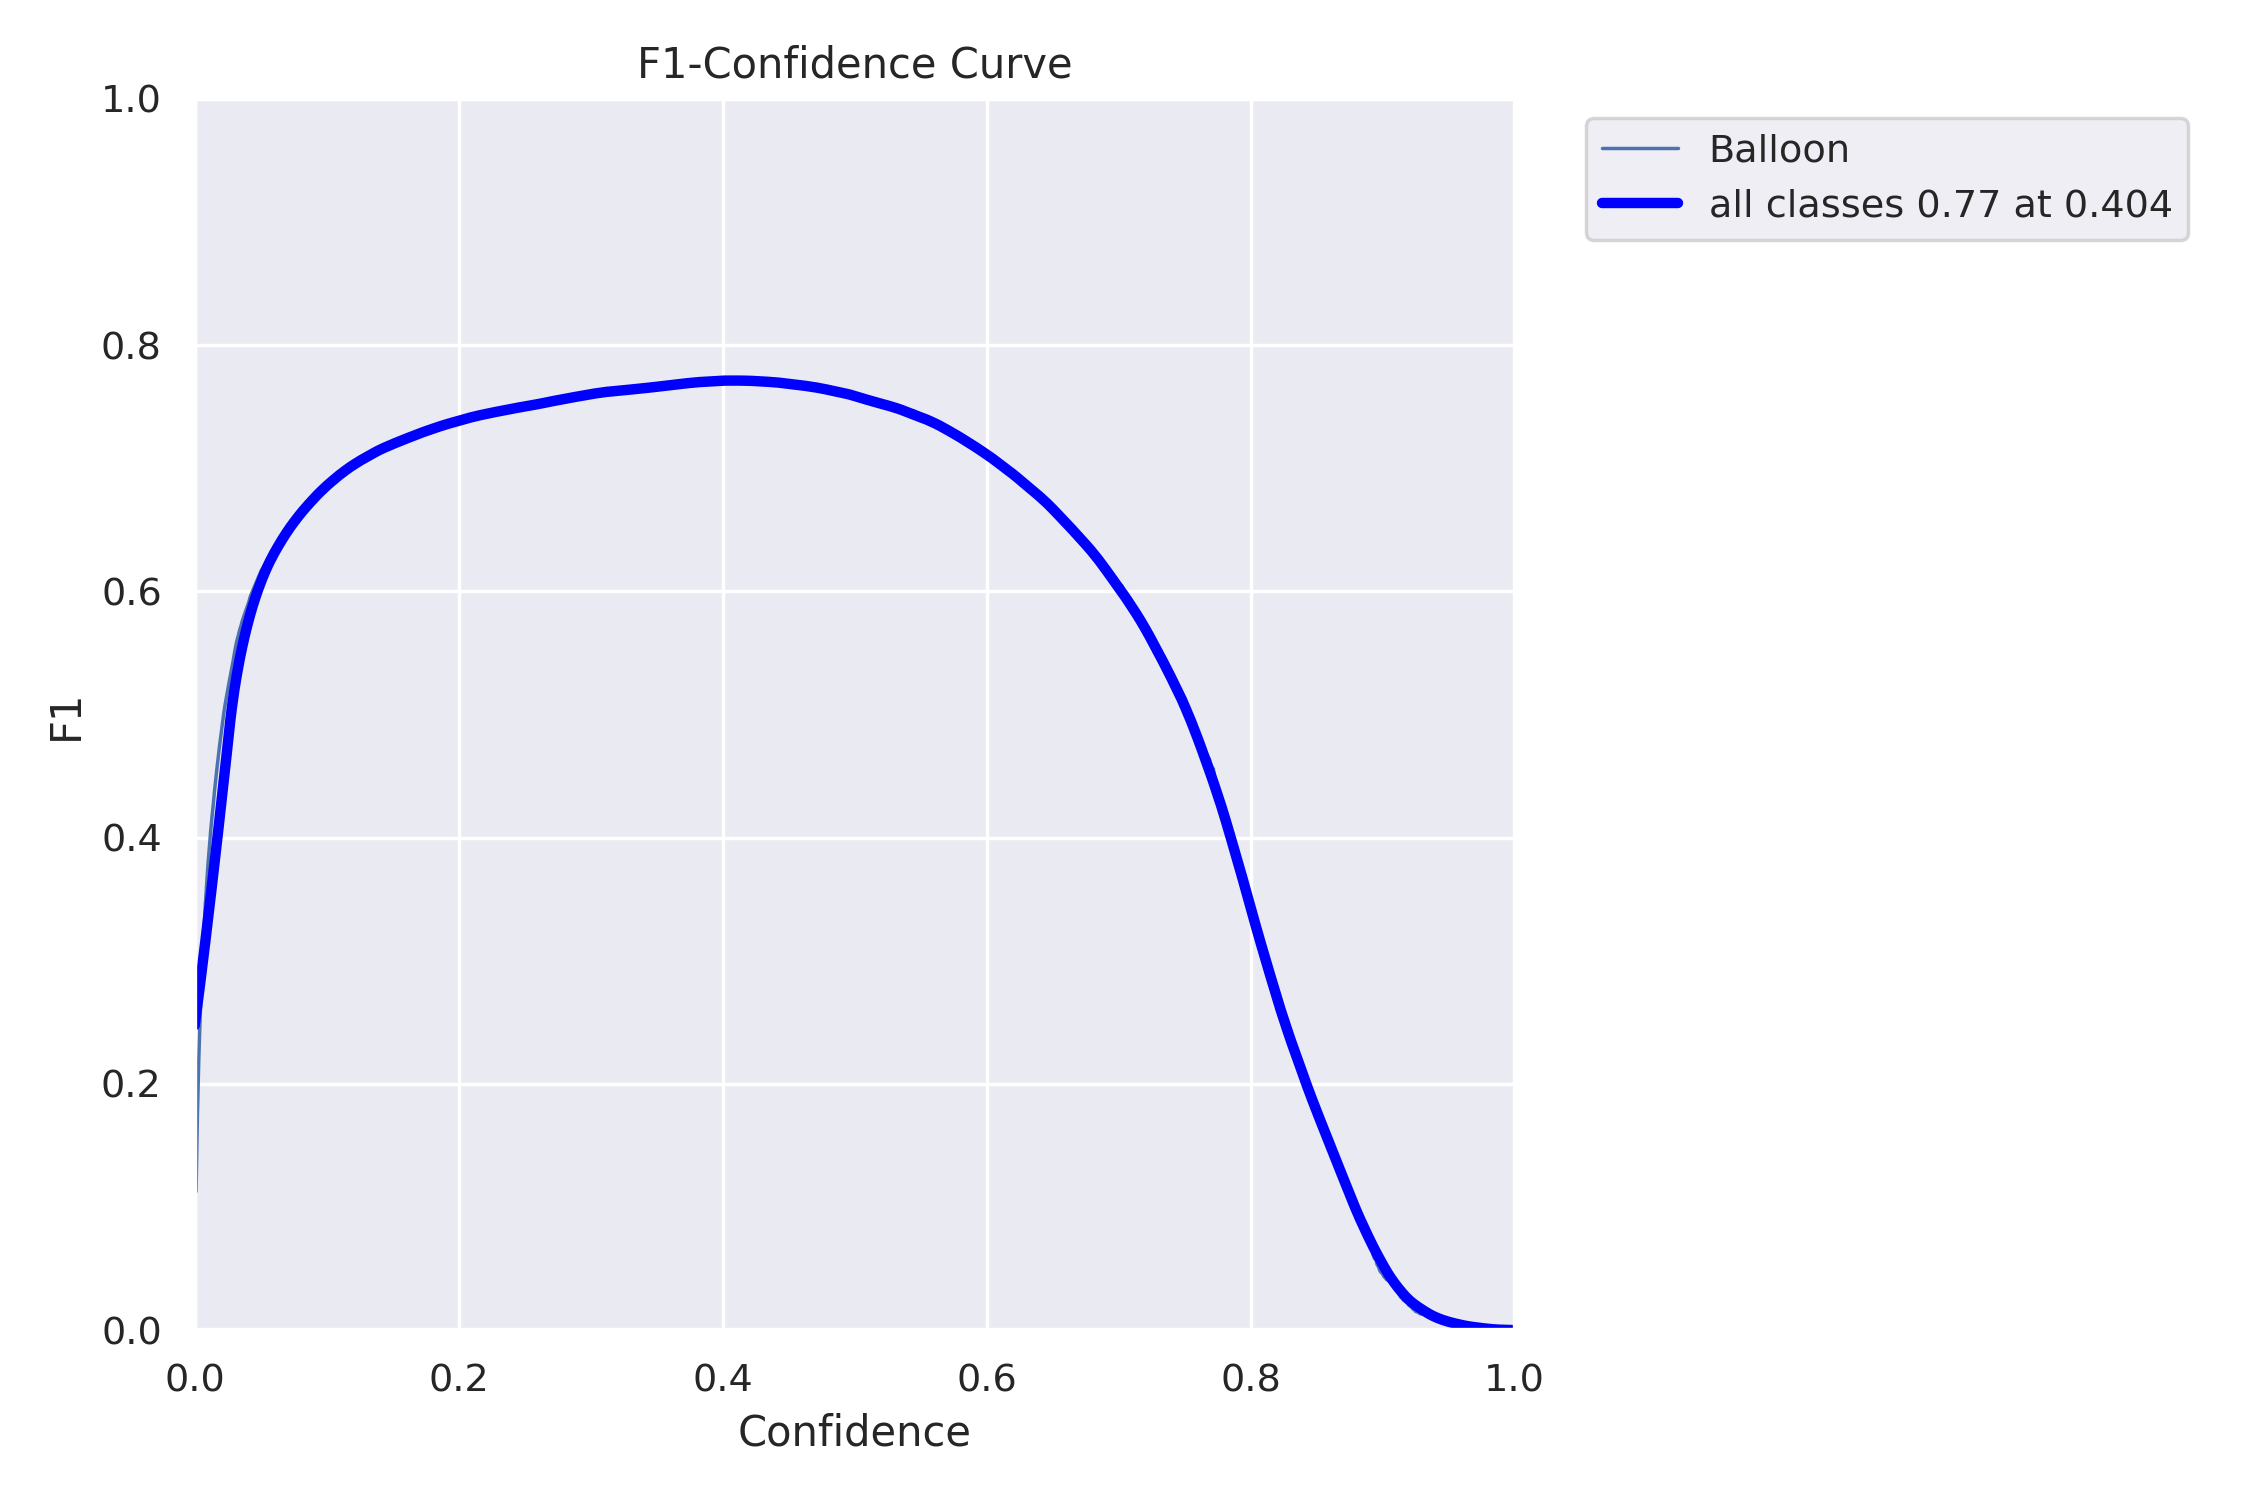

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_balloon_default/F1_curve.png', width=800)

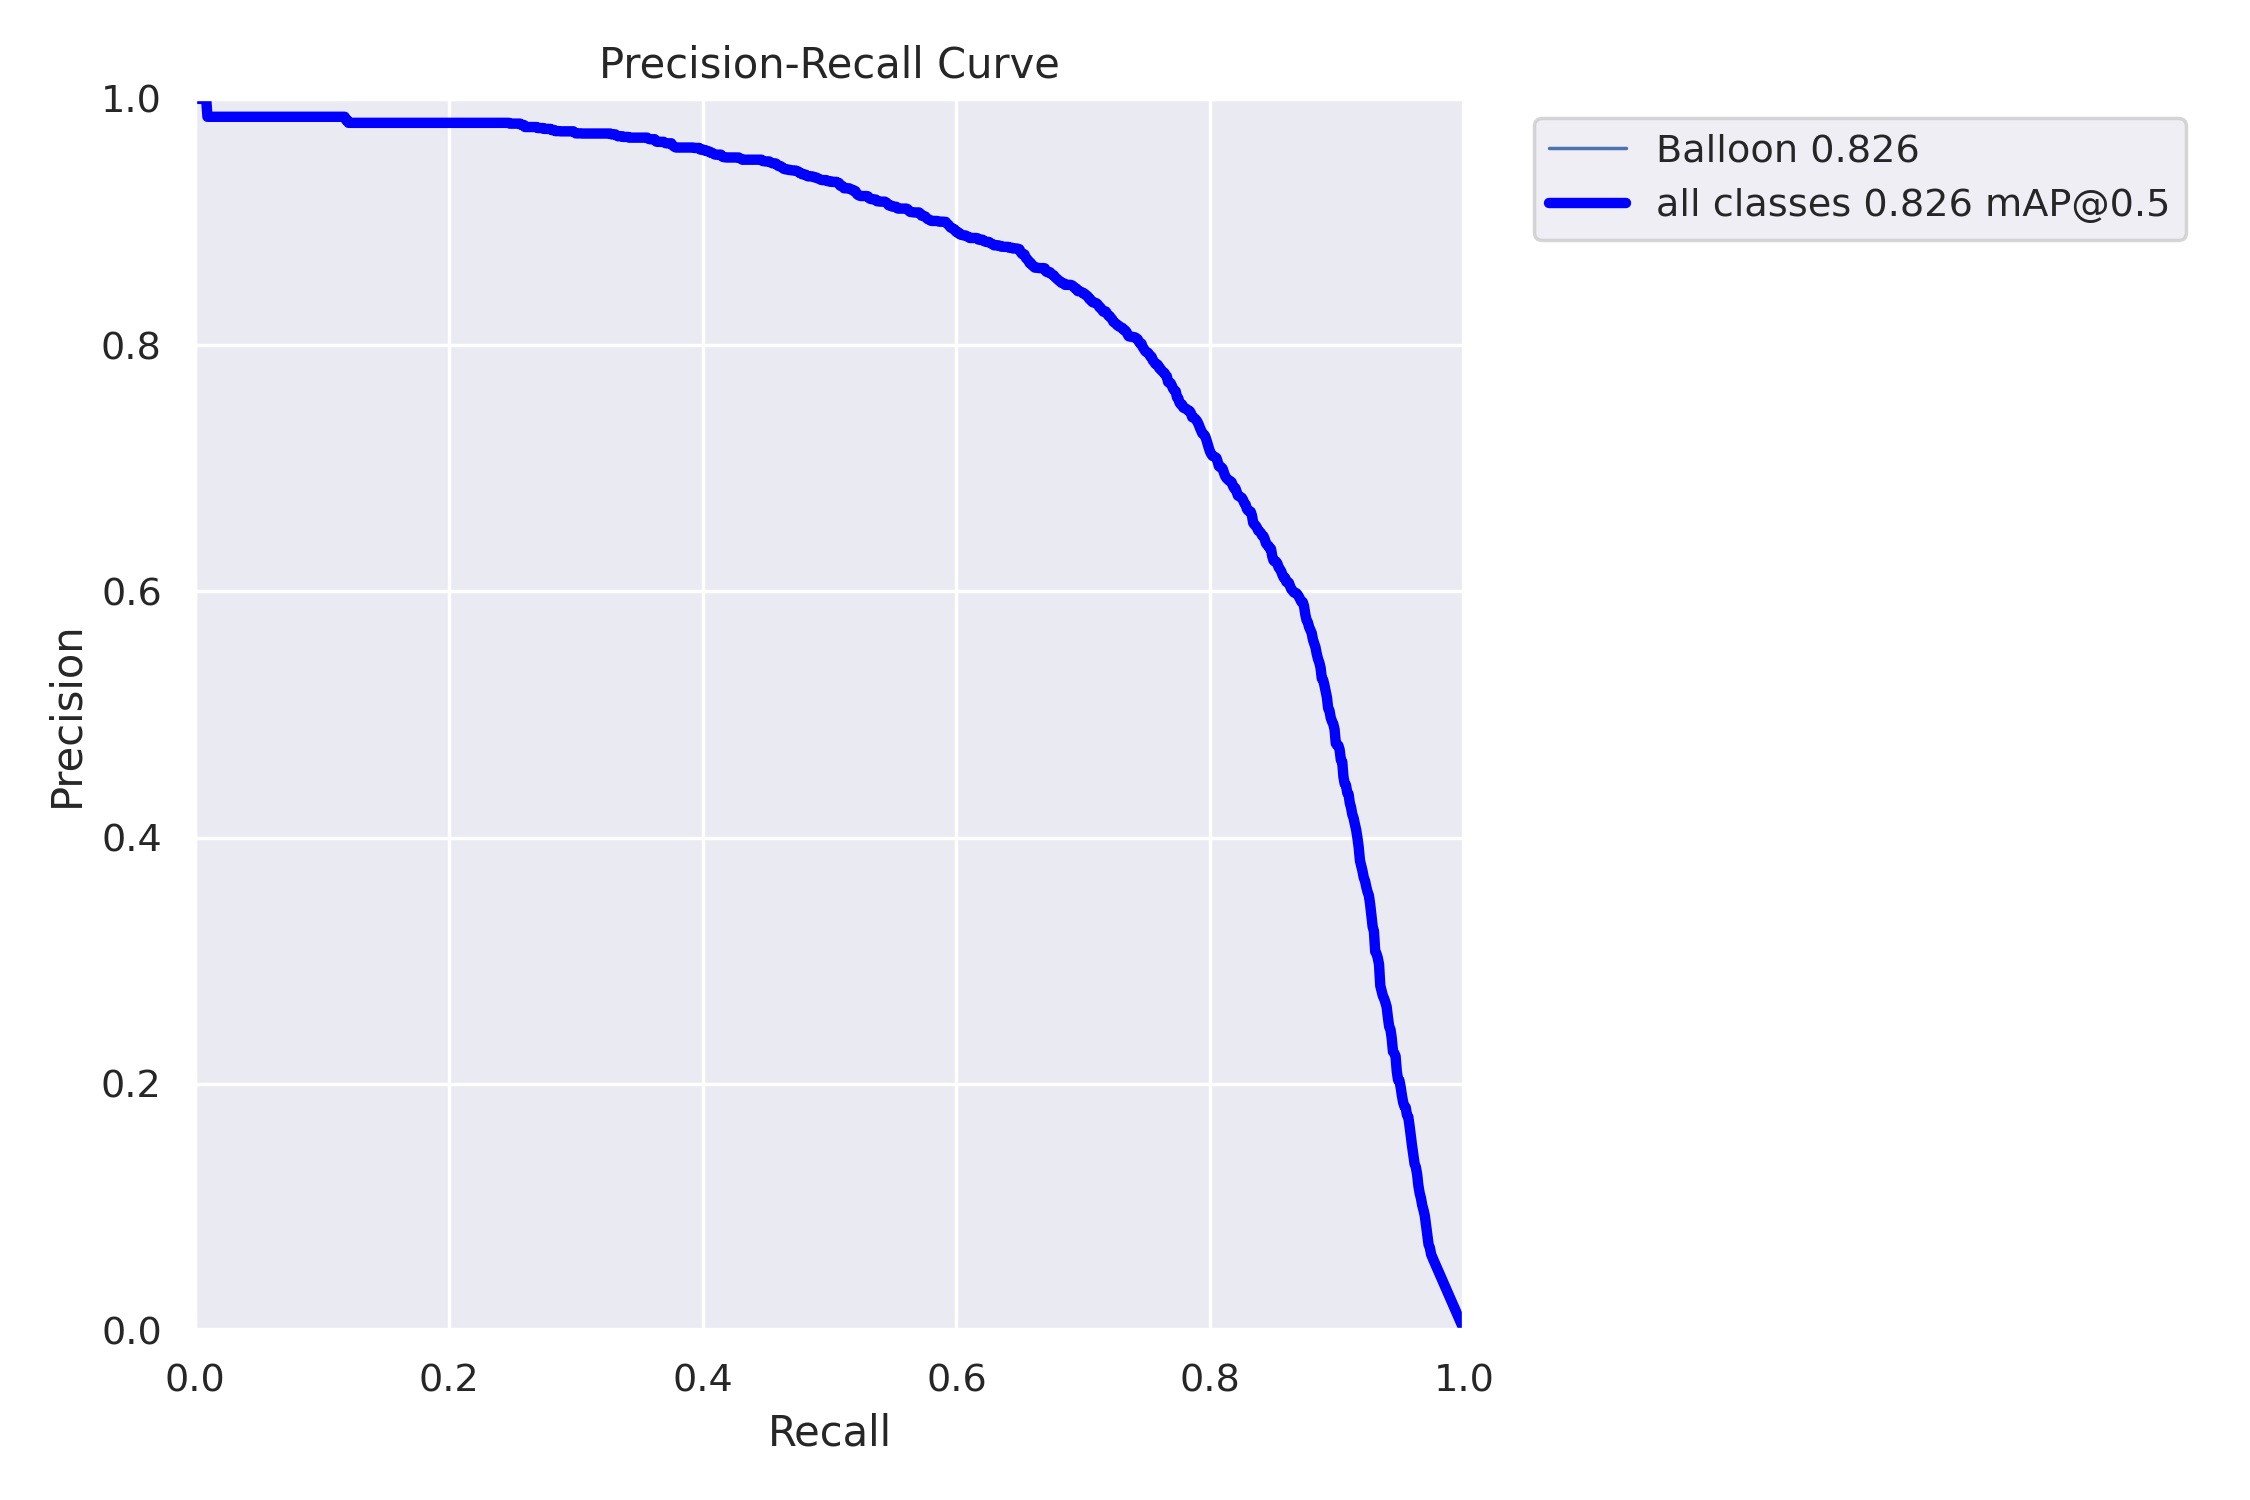

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_balloon_default/PR_curve.png', width=800)

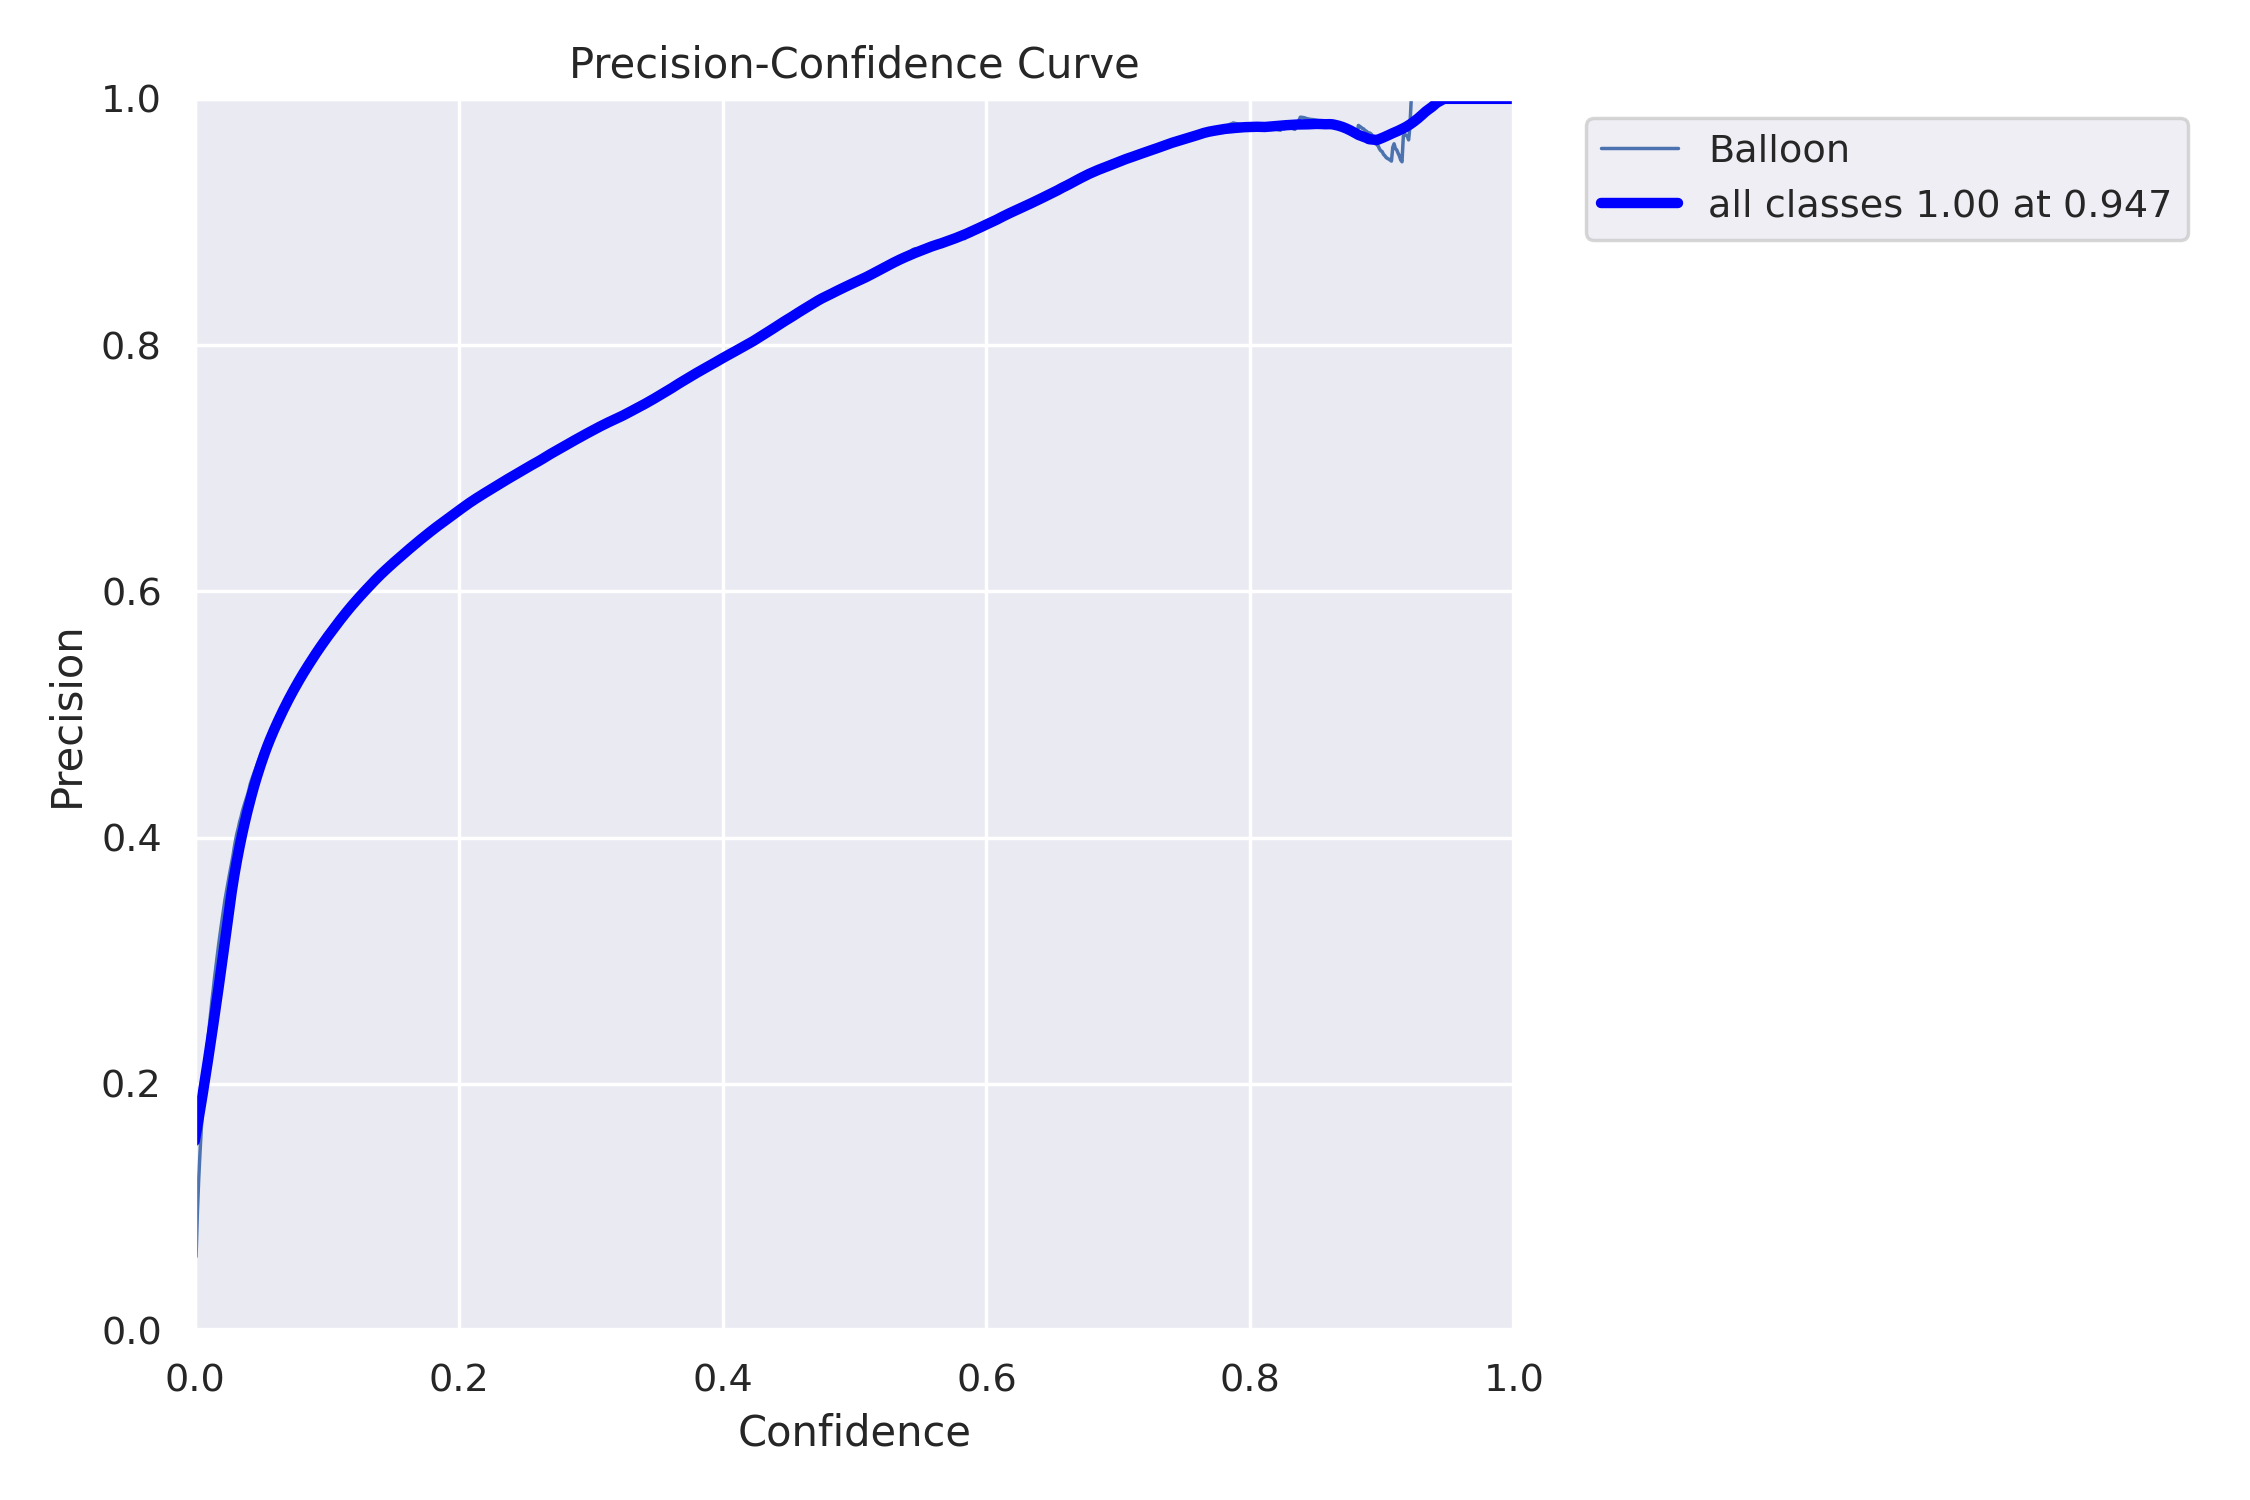

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_balloon_default/P_curve.png', width=800)

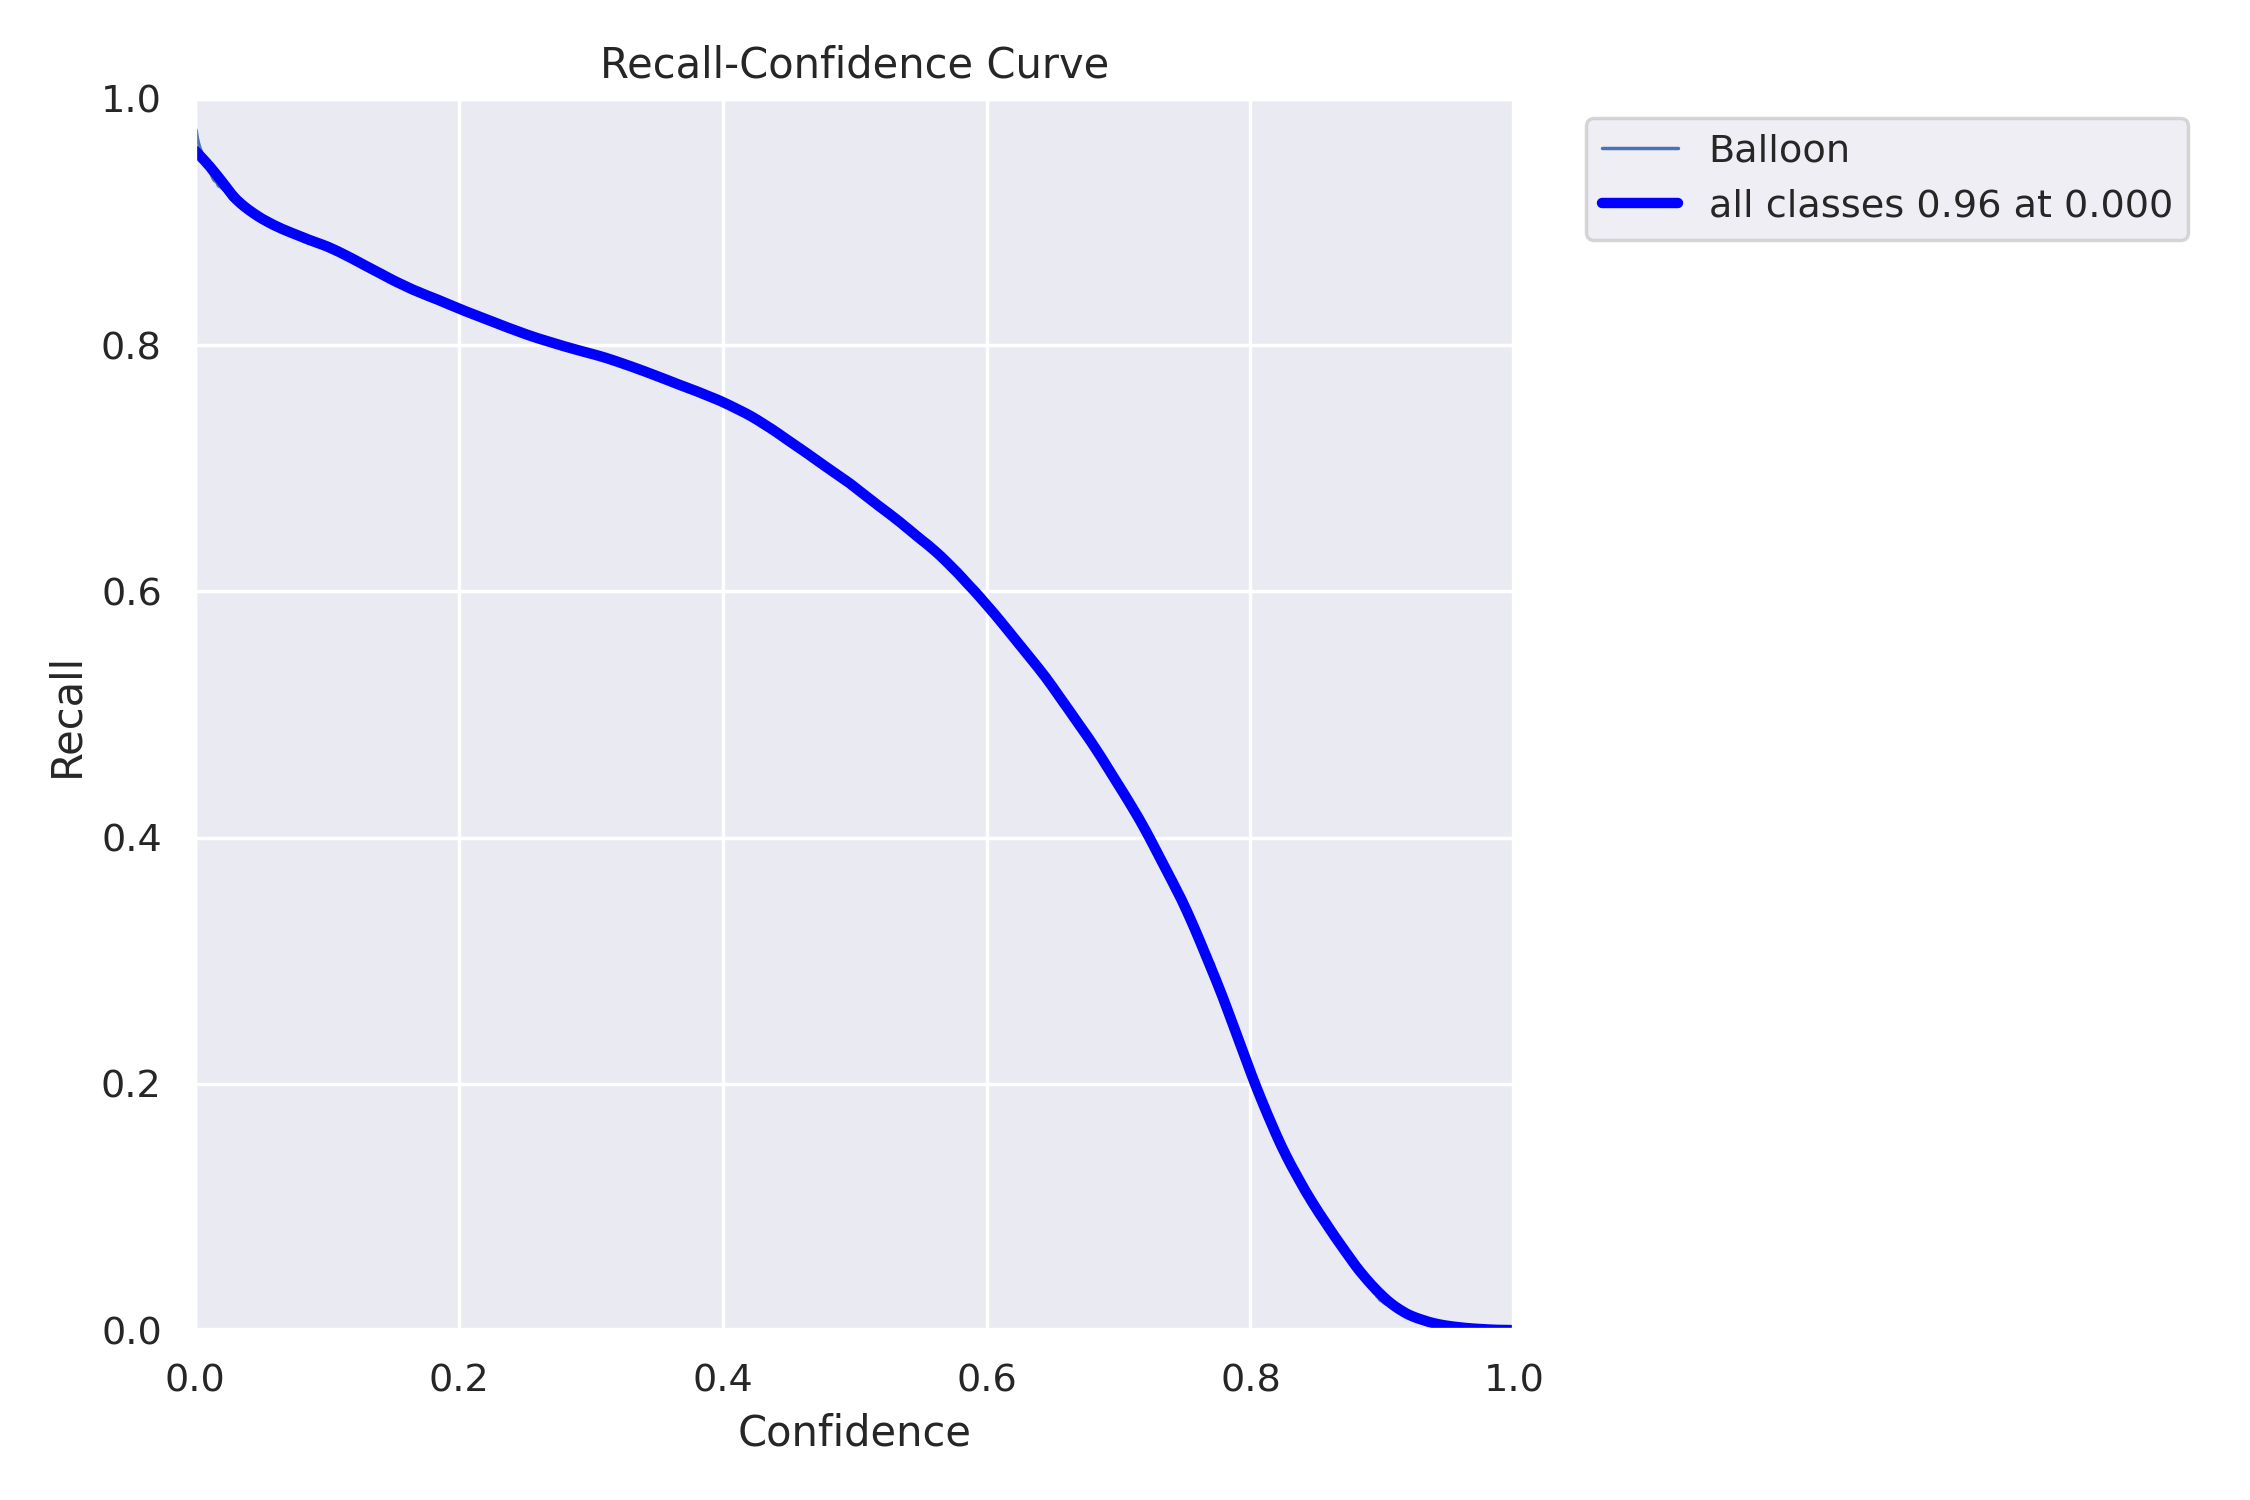

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_balloon_default/R_curve.png', width=800)

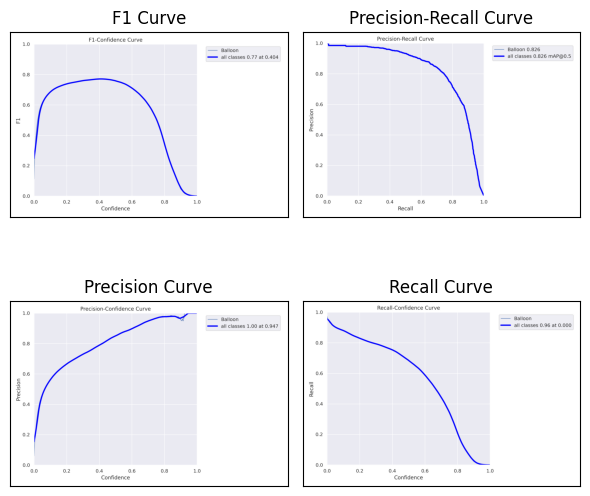

In [ ]:
image1 = plt.imread('/content/runs/detect/yolov8_balloon_default/F1_curve.png')
image2 = plt.imread('/content/runs/detect/yolov8_balloon_default/PR_curve.png')
image3 = plt.imread('/content/runs/detect/yolov8_balloon_default/P_curve.png')
image4 = plt.imread('/content/runs/detect/yolov8_balloon_default/R_curve.png')

fig, axs = plt.subplots(2, 2, figsize=(6, 6))

axs[0, 0].imshow(image1)
axs[0, 0].set_title('F1 Curve')

axs[0, 1].imshow(image2)
axs[0, 1].set_title('Precision-Recall Curve')

axs[1, 0].imshow(image3)
axs[1, 0].set_title('Precision Curve')
axs[1, 1].imshow(image4)
axs[1, 1].set_title('Recall Curve')

for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

#Hyperparameter Tuning

In [ ]:
!yolo detect train model=yolov8l.pt data=/content/Blimp_Yolo_v8_Custom-1/data.yaml name=yolov8_ballon_tuning device=0 epochs=30 patience=20 workers=2 batch=12 lr0=0.01 momentum=0.95 weight_decay=0.0001 warmup_epochs=10 warmup_momentum=0.5 warmup_bias_lr=0.1 optimizer=SGD

Ultralytics YOLOv8.0.20 🚀 Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
yolo/engine/trainer: task=detect, mode=train, model=yolov8l.yaml, data=/content/Blimp_Yolo_v8_Custom-1/data.yaml, epochs=30, patience=20, batch=12, imgsz=640, save=True, cache=False, device=0, workers=2, project=None, name=yolov8_ballon_tuning, exist_ok=False, pretrained=False, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, image_weights=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, overlap_mask=True, mask_ratio=4, dropout=False, val=True, save_json=False, save_hybrid=False, conf=0.001, iou=0.7, max_det=300, half=False, dnn=False, plots=False, source=ultralytics/assets/, show=False, save_txt=False, save_conf=False, save_crop=False, hide_labels=False, hide_conf=False, vid_stride=1, line_thickness=3, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, boxes=True, format=torchscript, keras=False, optimize=False, int8=False, 

**After tuning we got 0.84 mAP :) using SGD optimizer with momentuom**

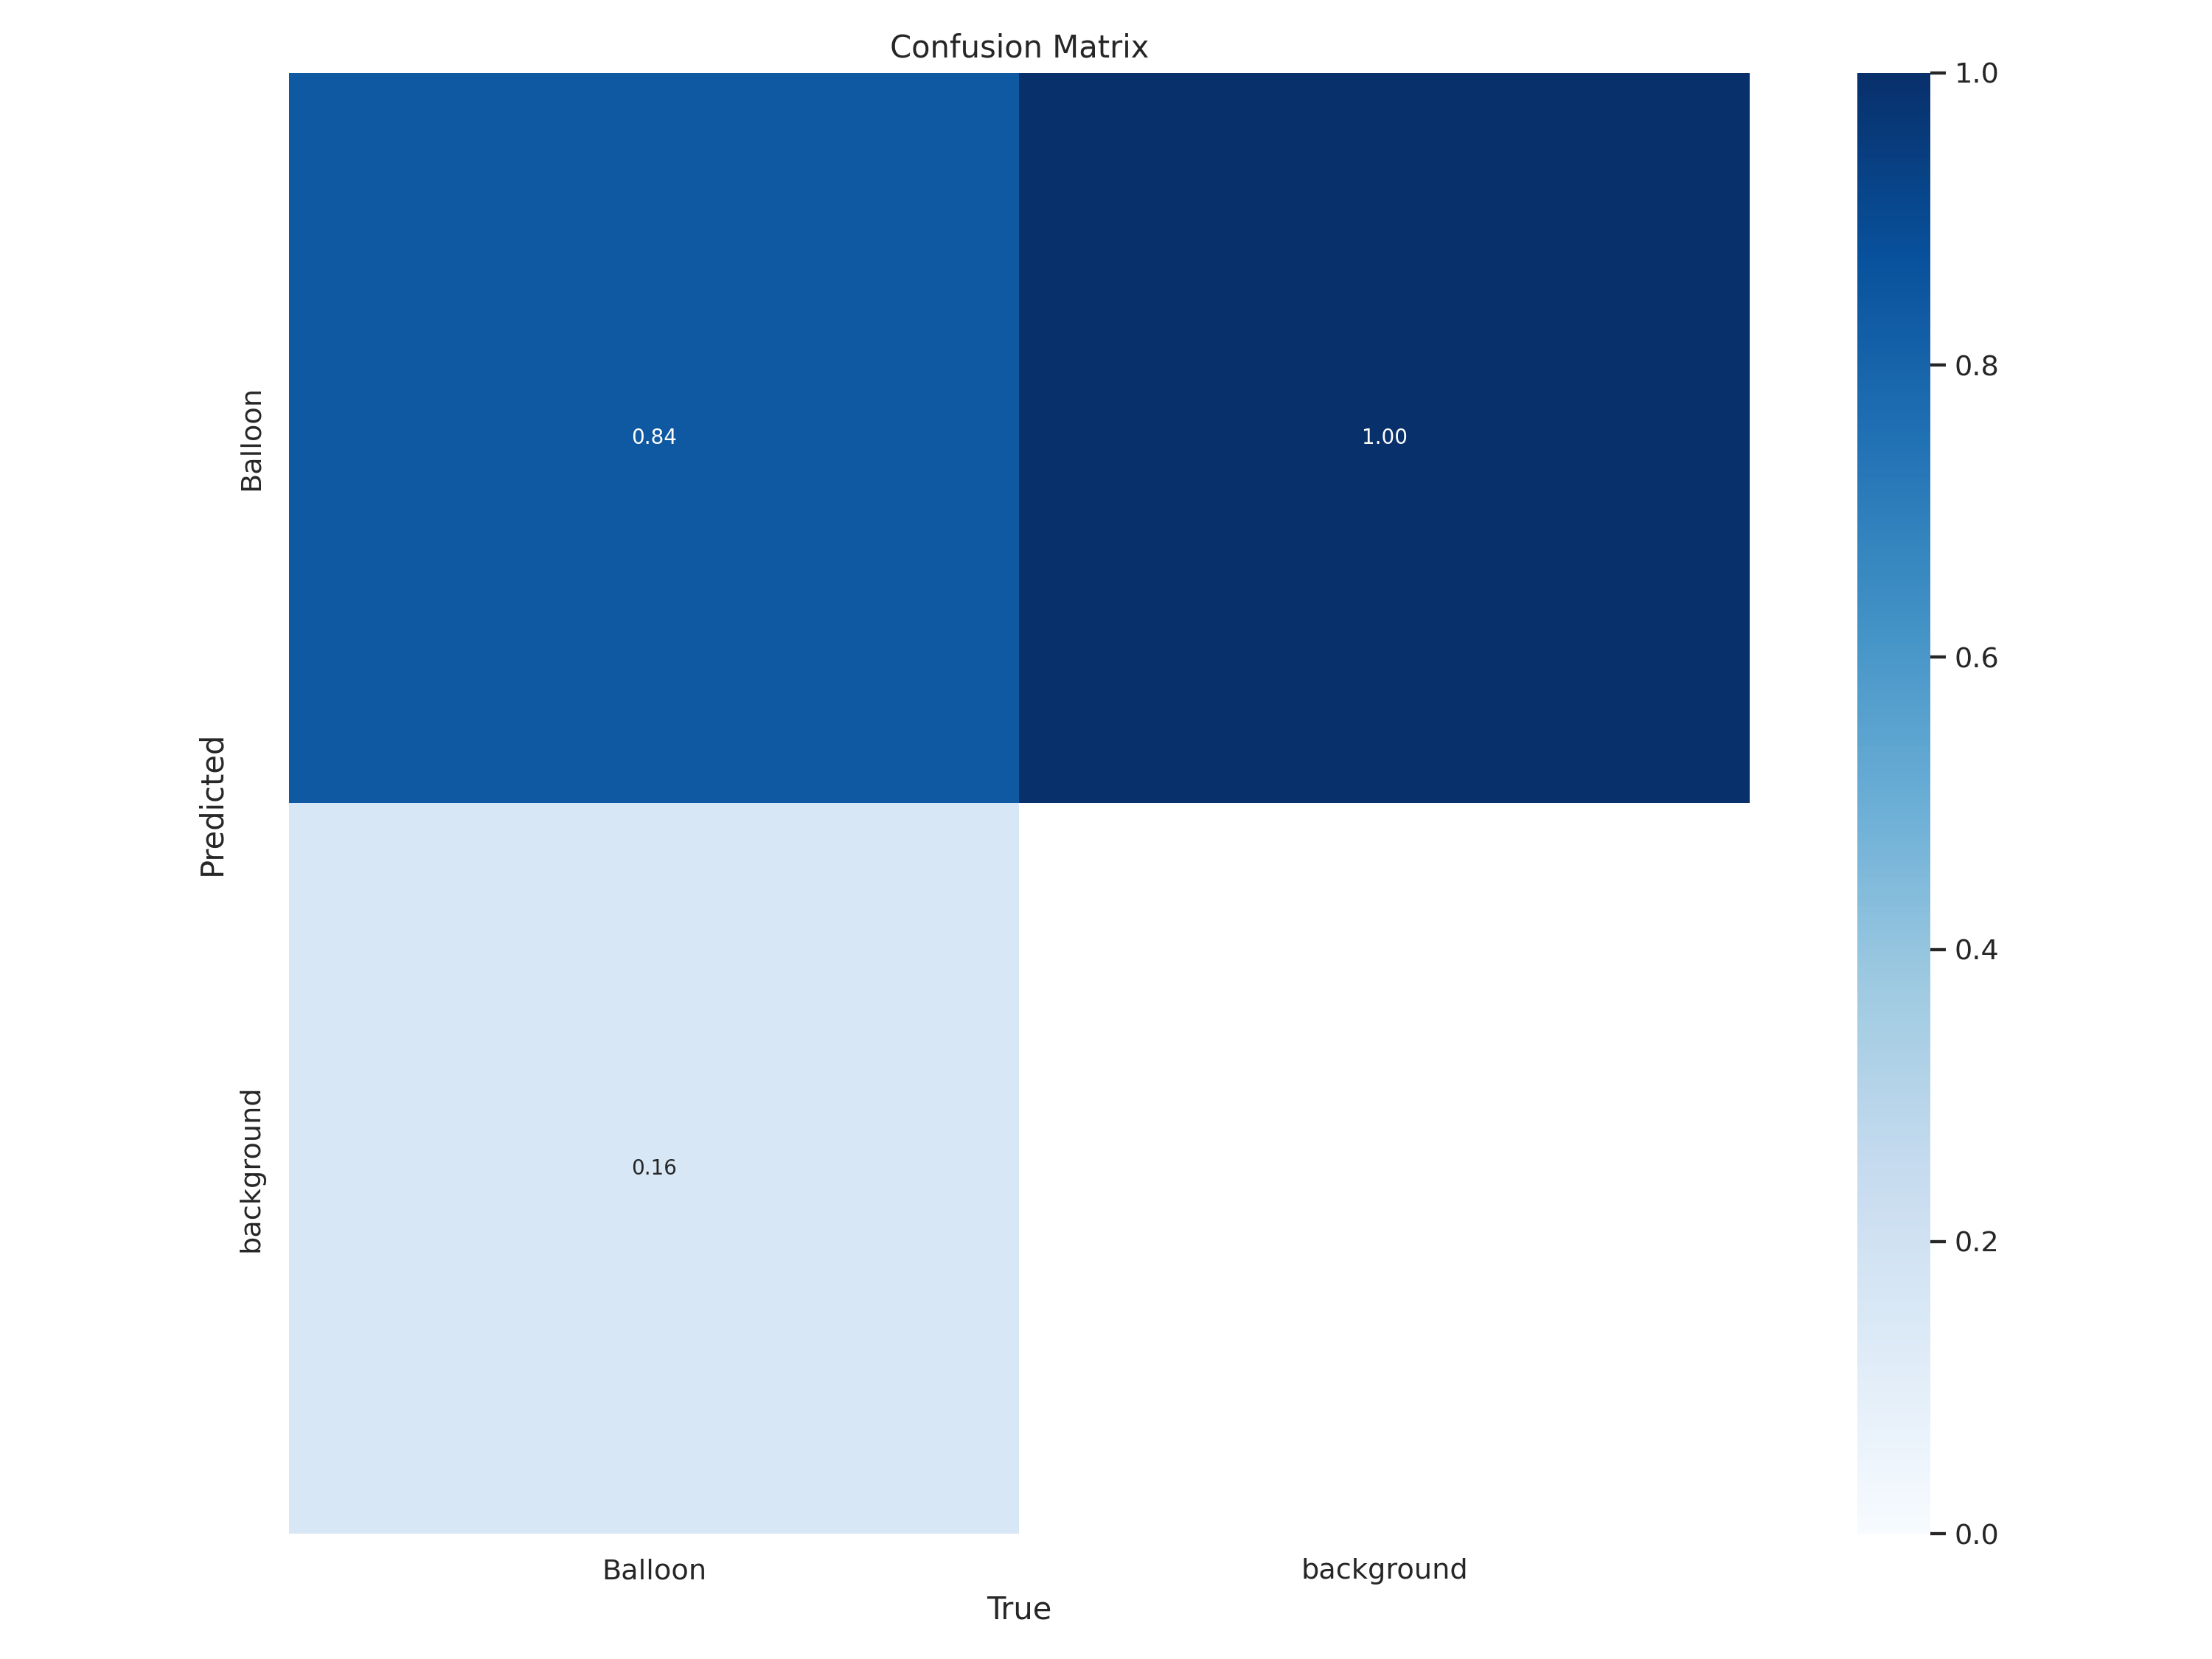

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_ballon_tuning/confusion_matrix.png', width=800)

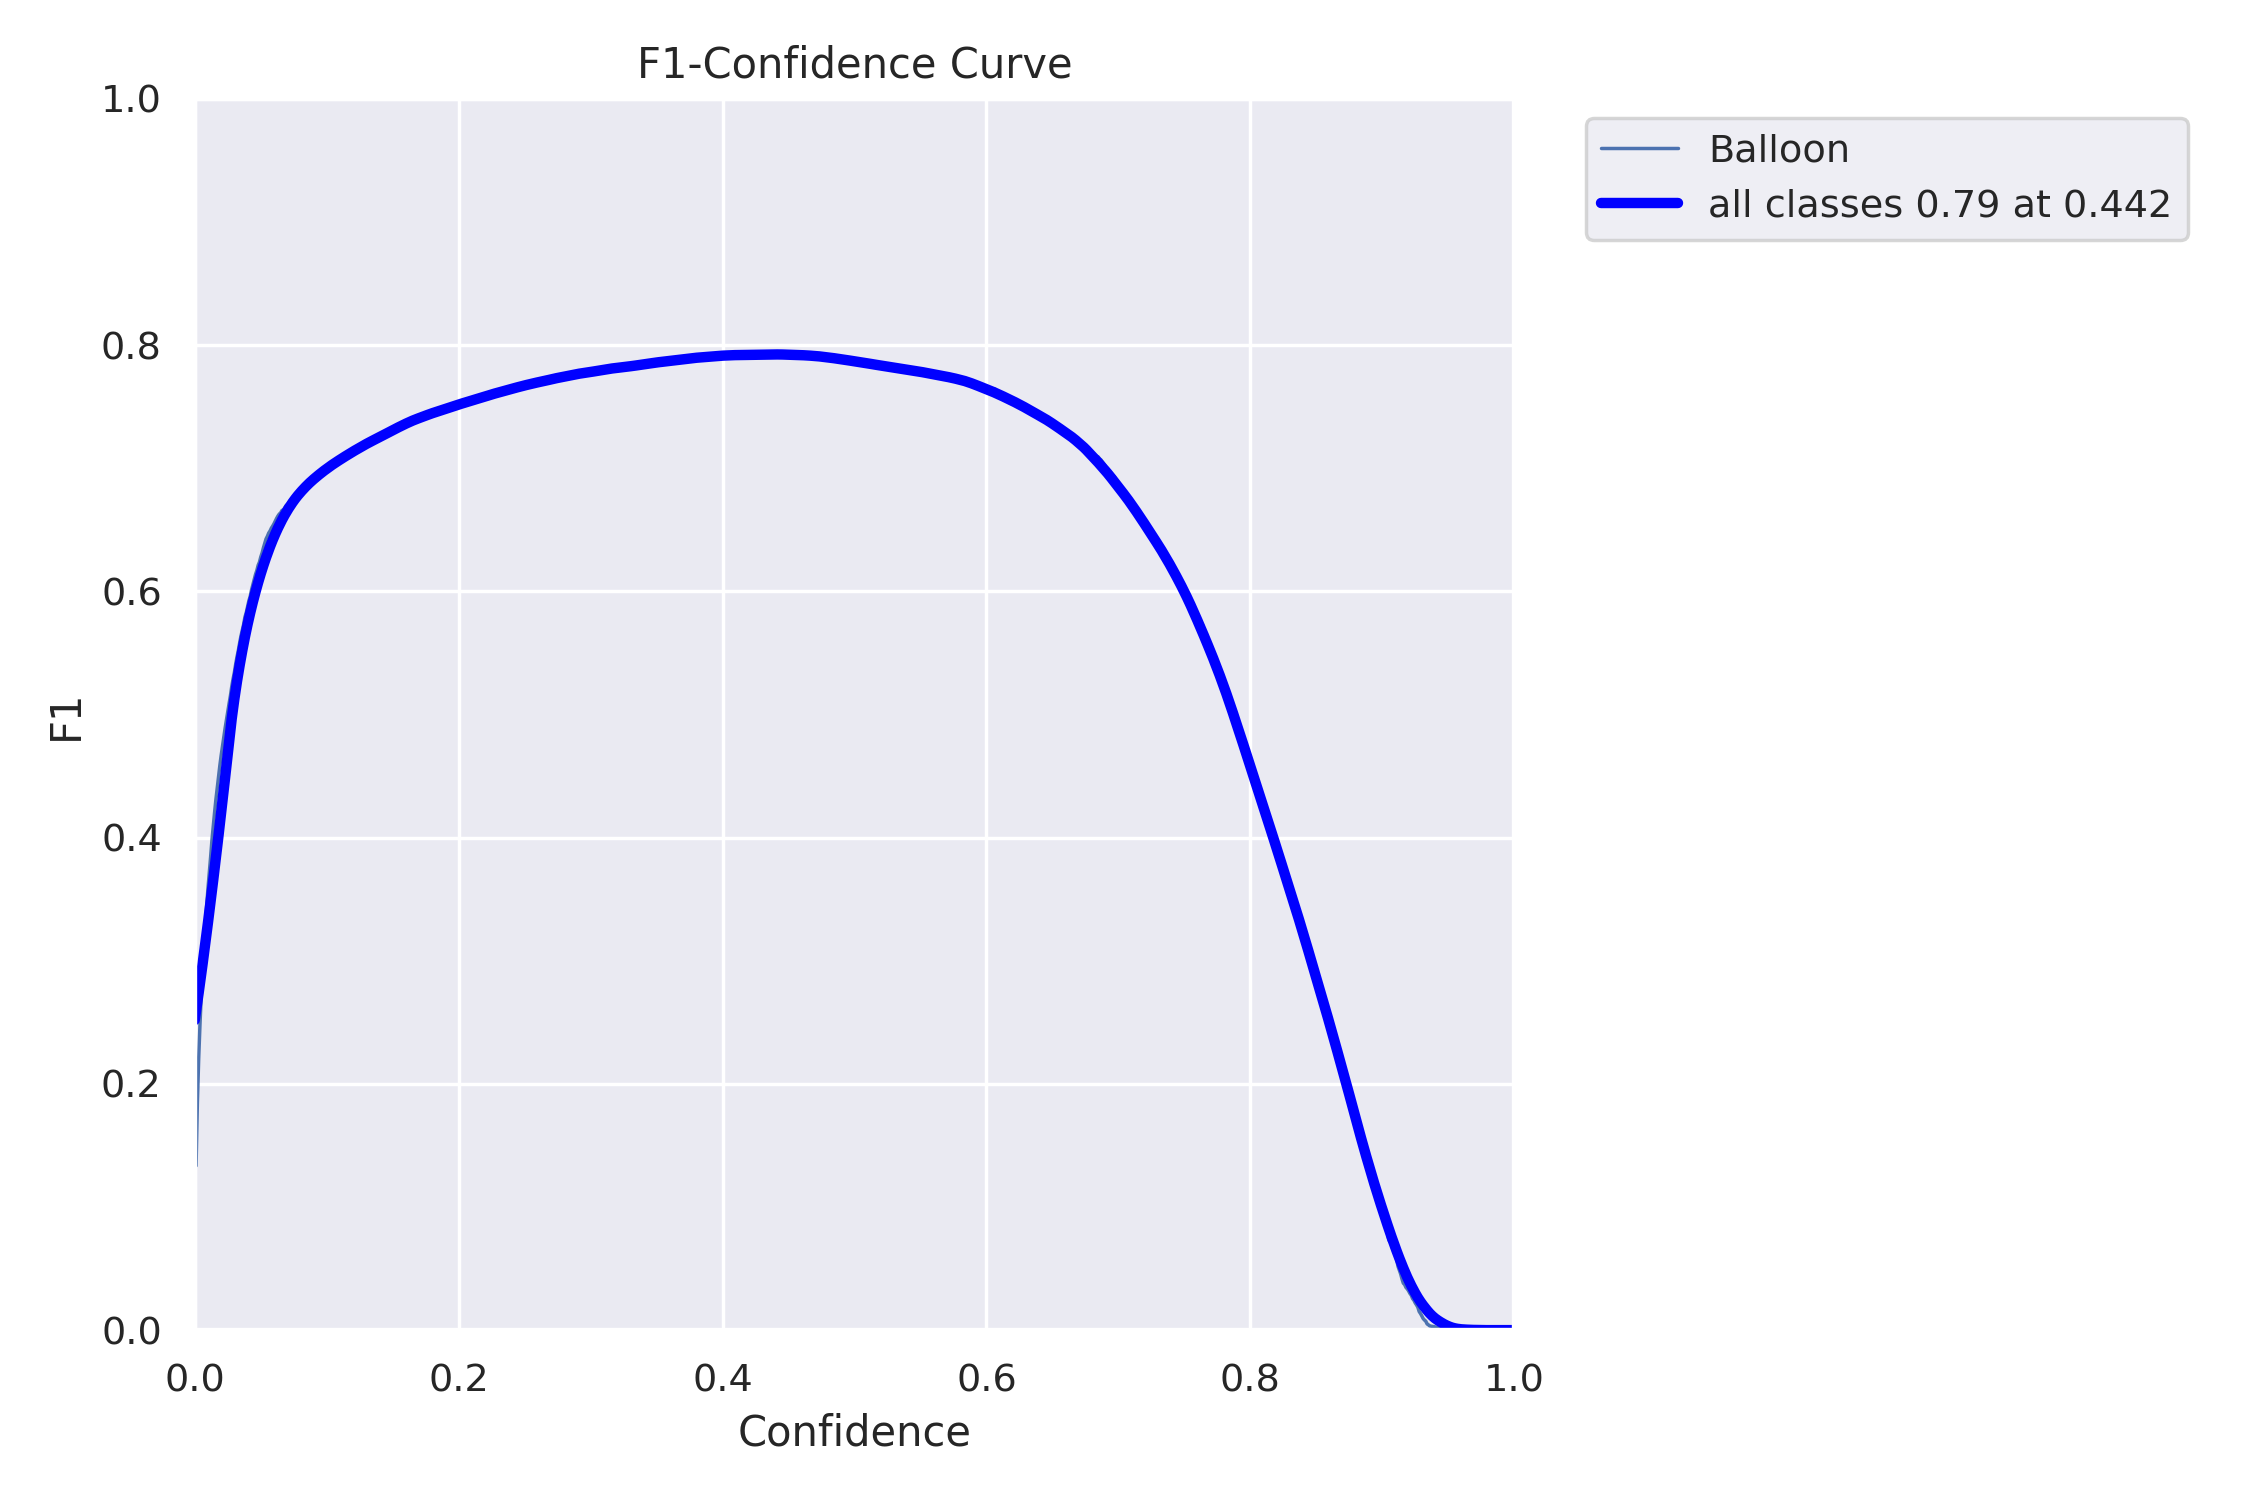

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_ballon_tuning/F1_curve.png', width=800)

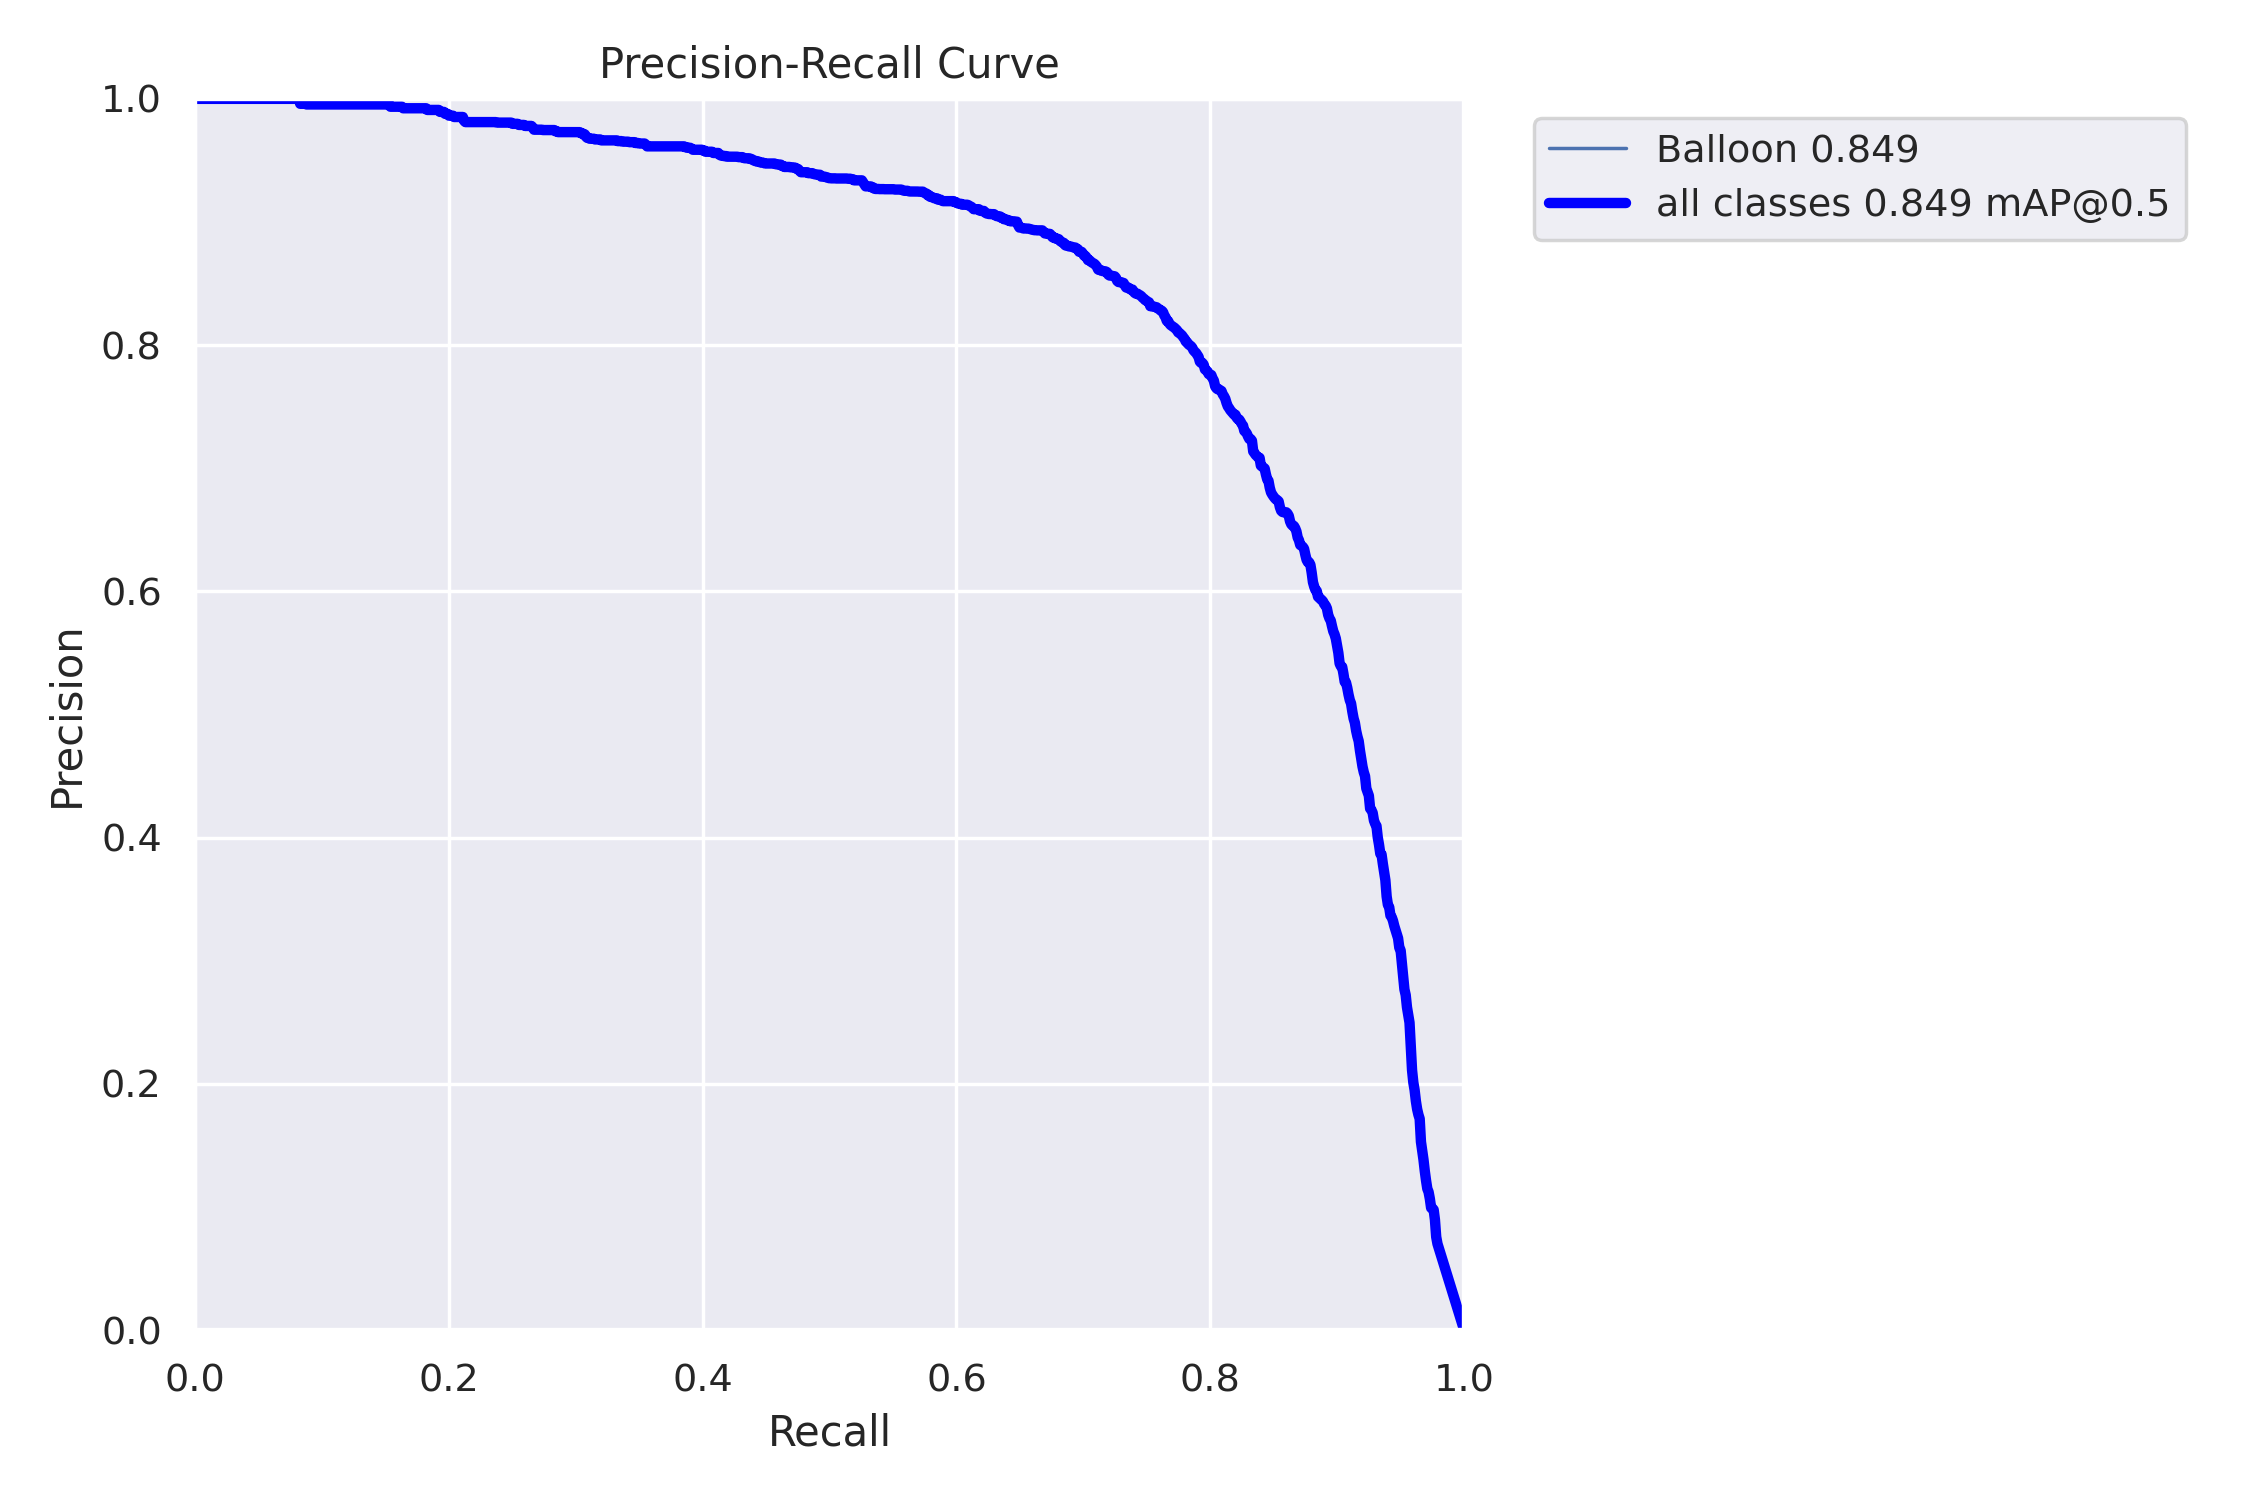

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_ballon_tuning/PR_curve.png', width=800)

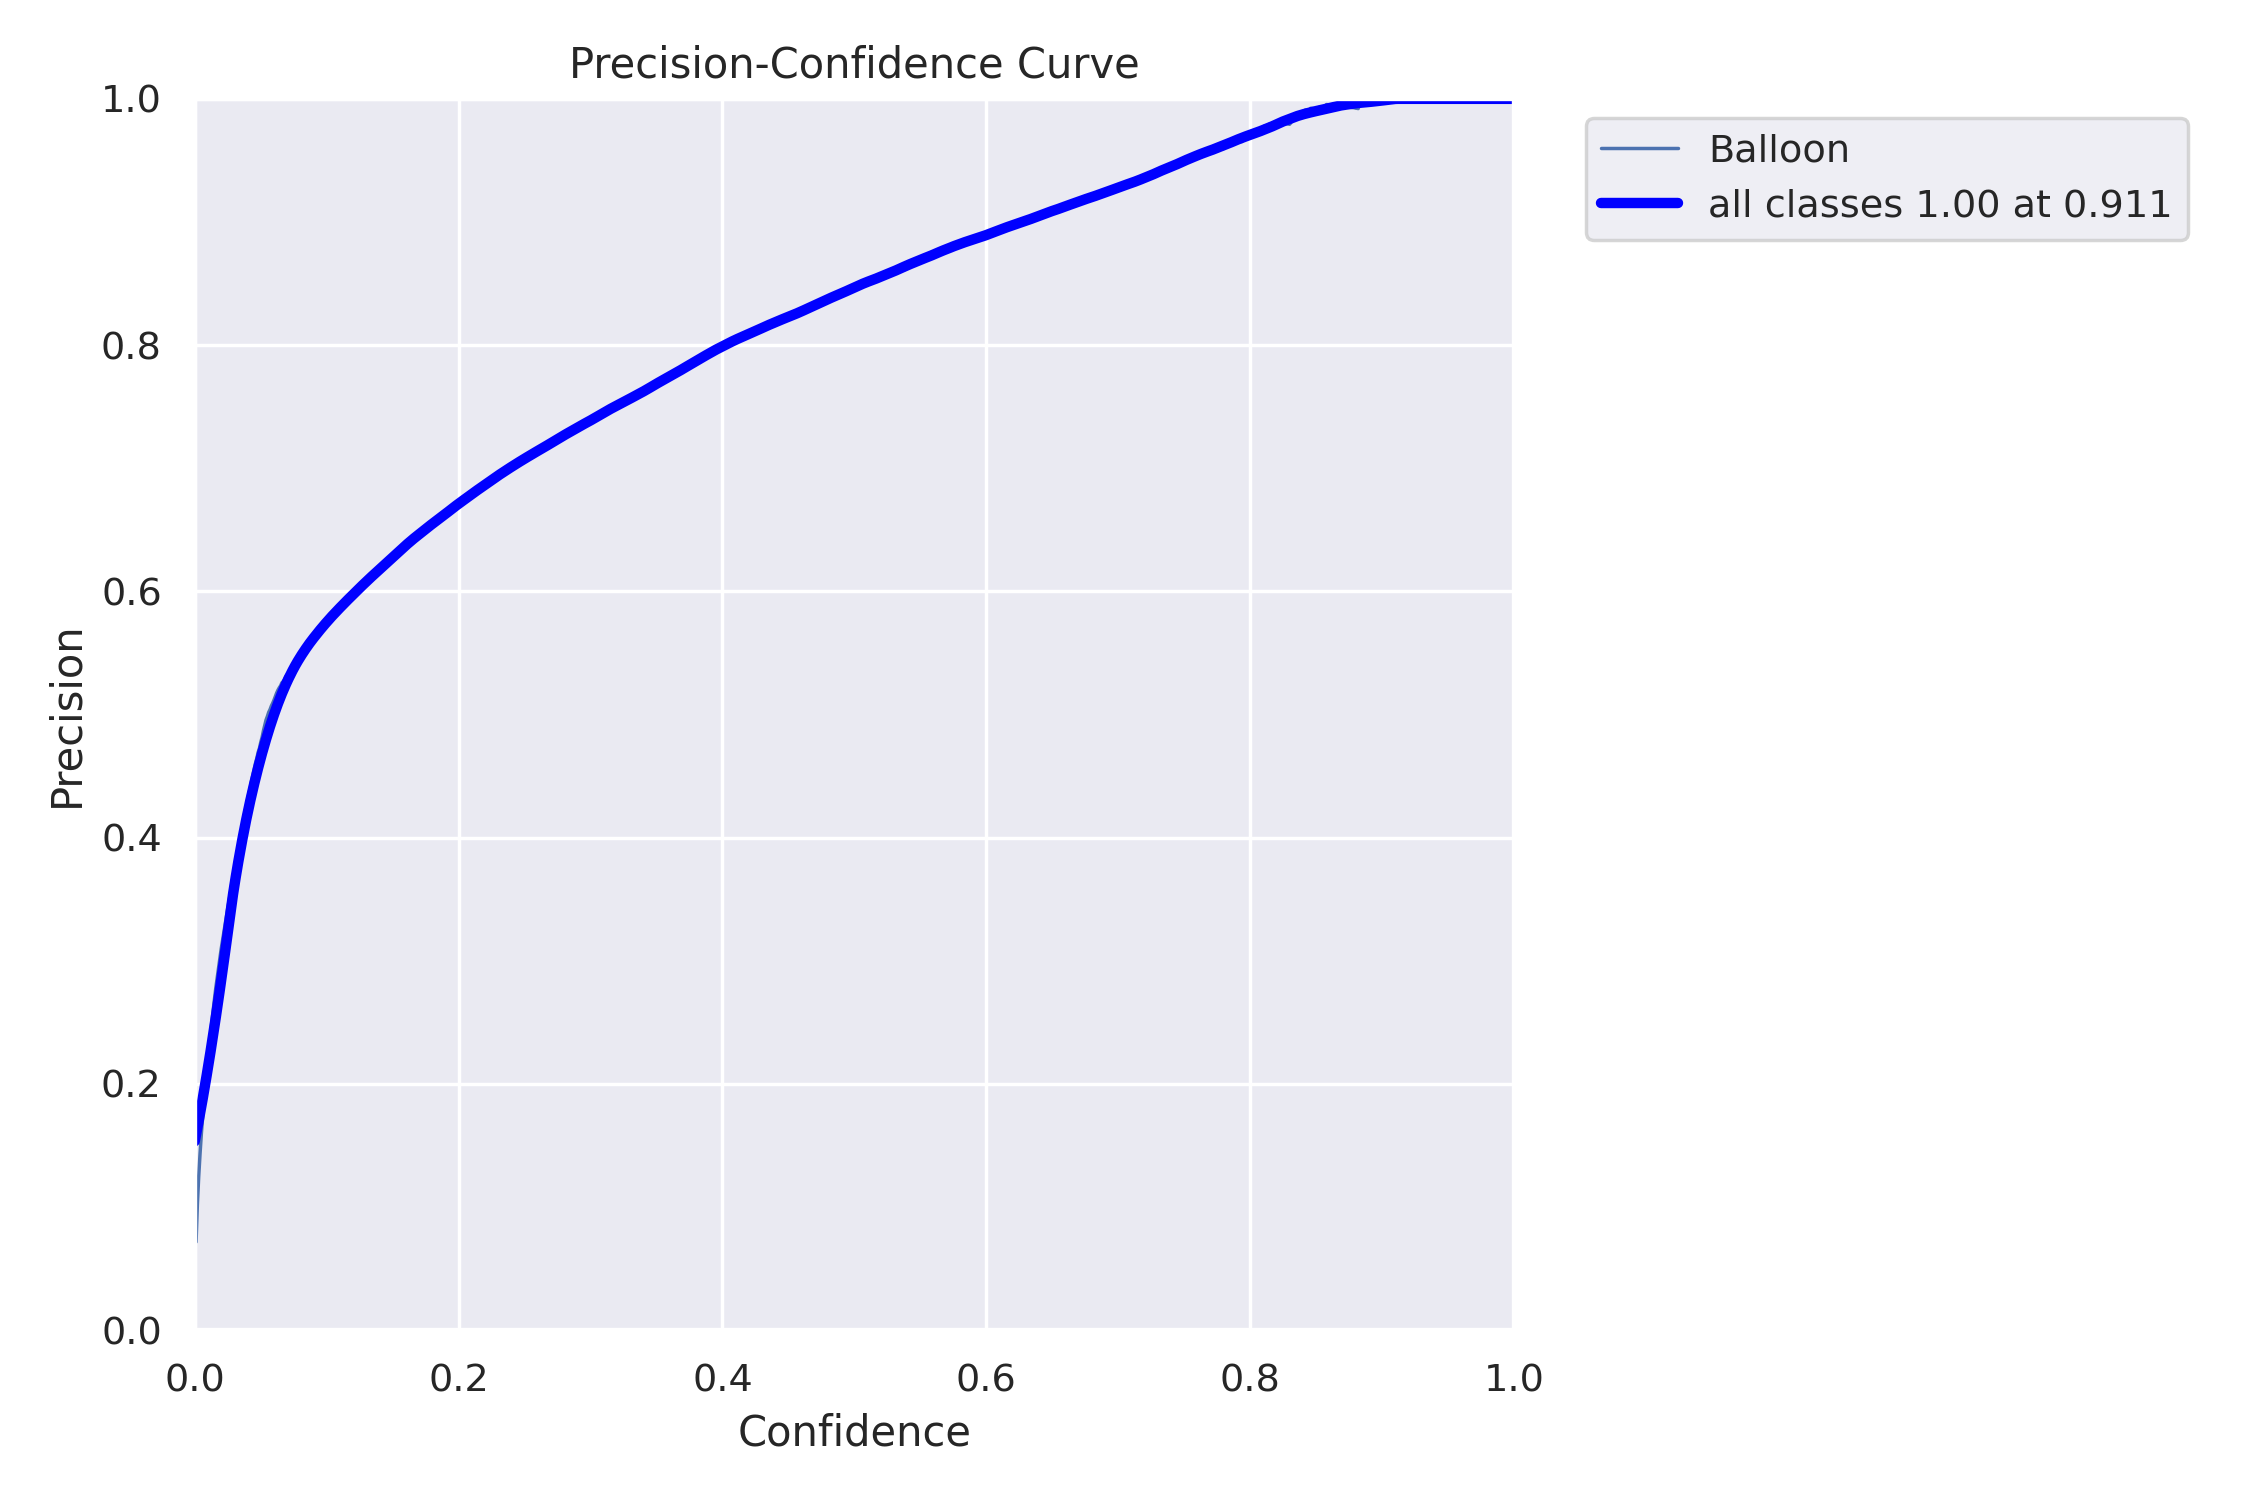

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_ballon_tuning/P_curve.png', width=800)

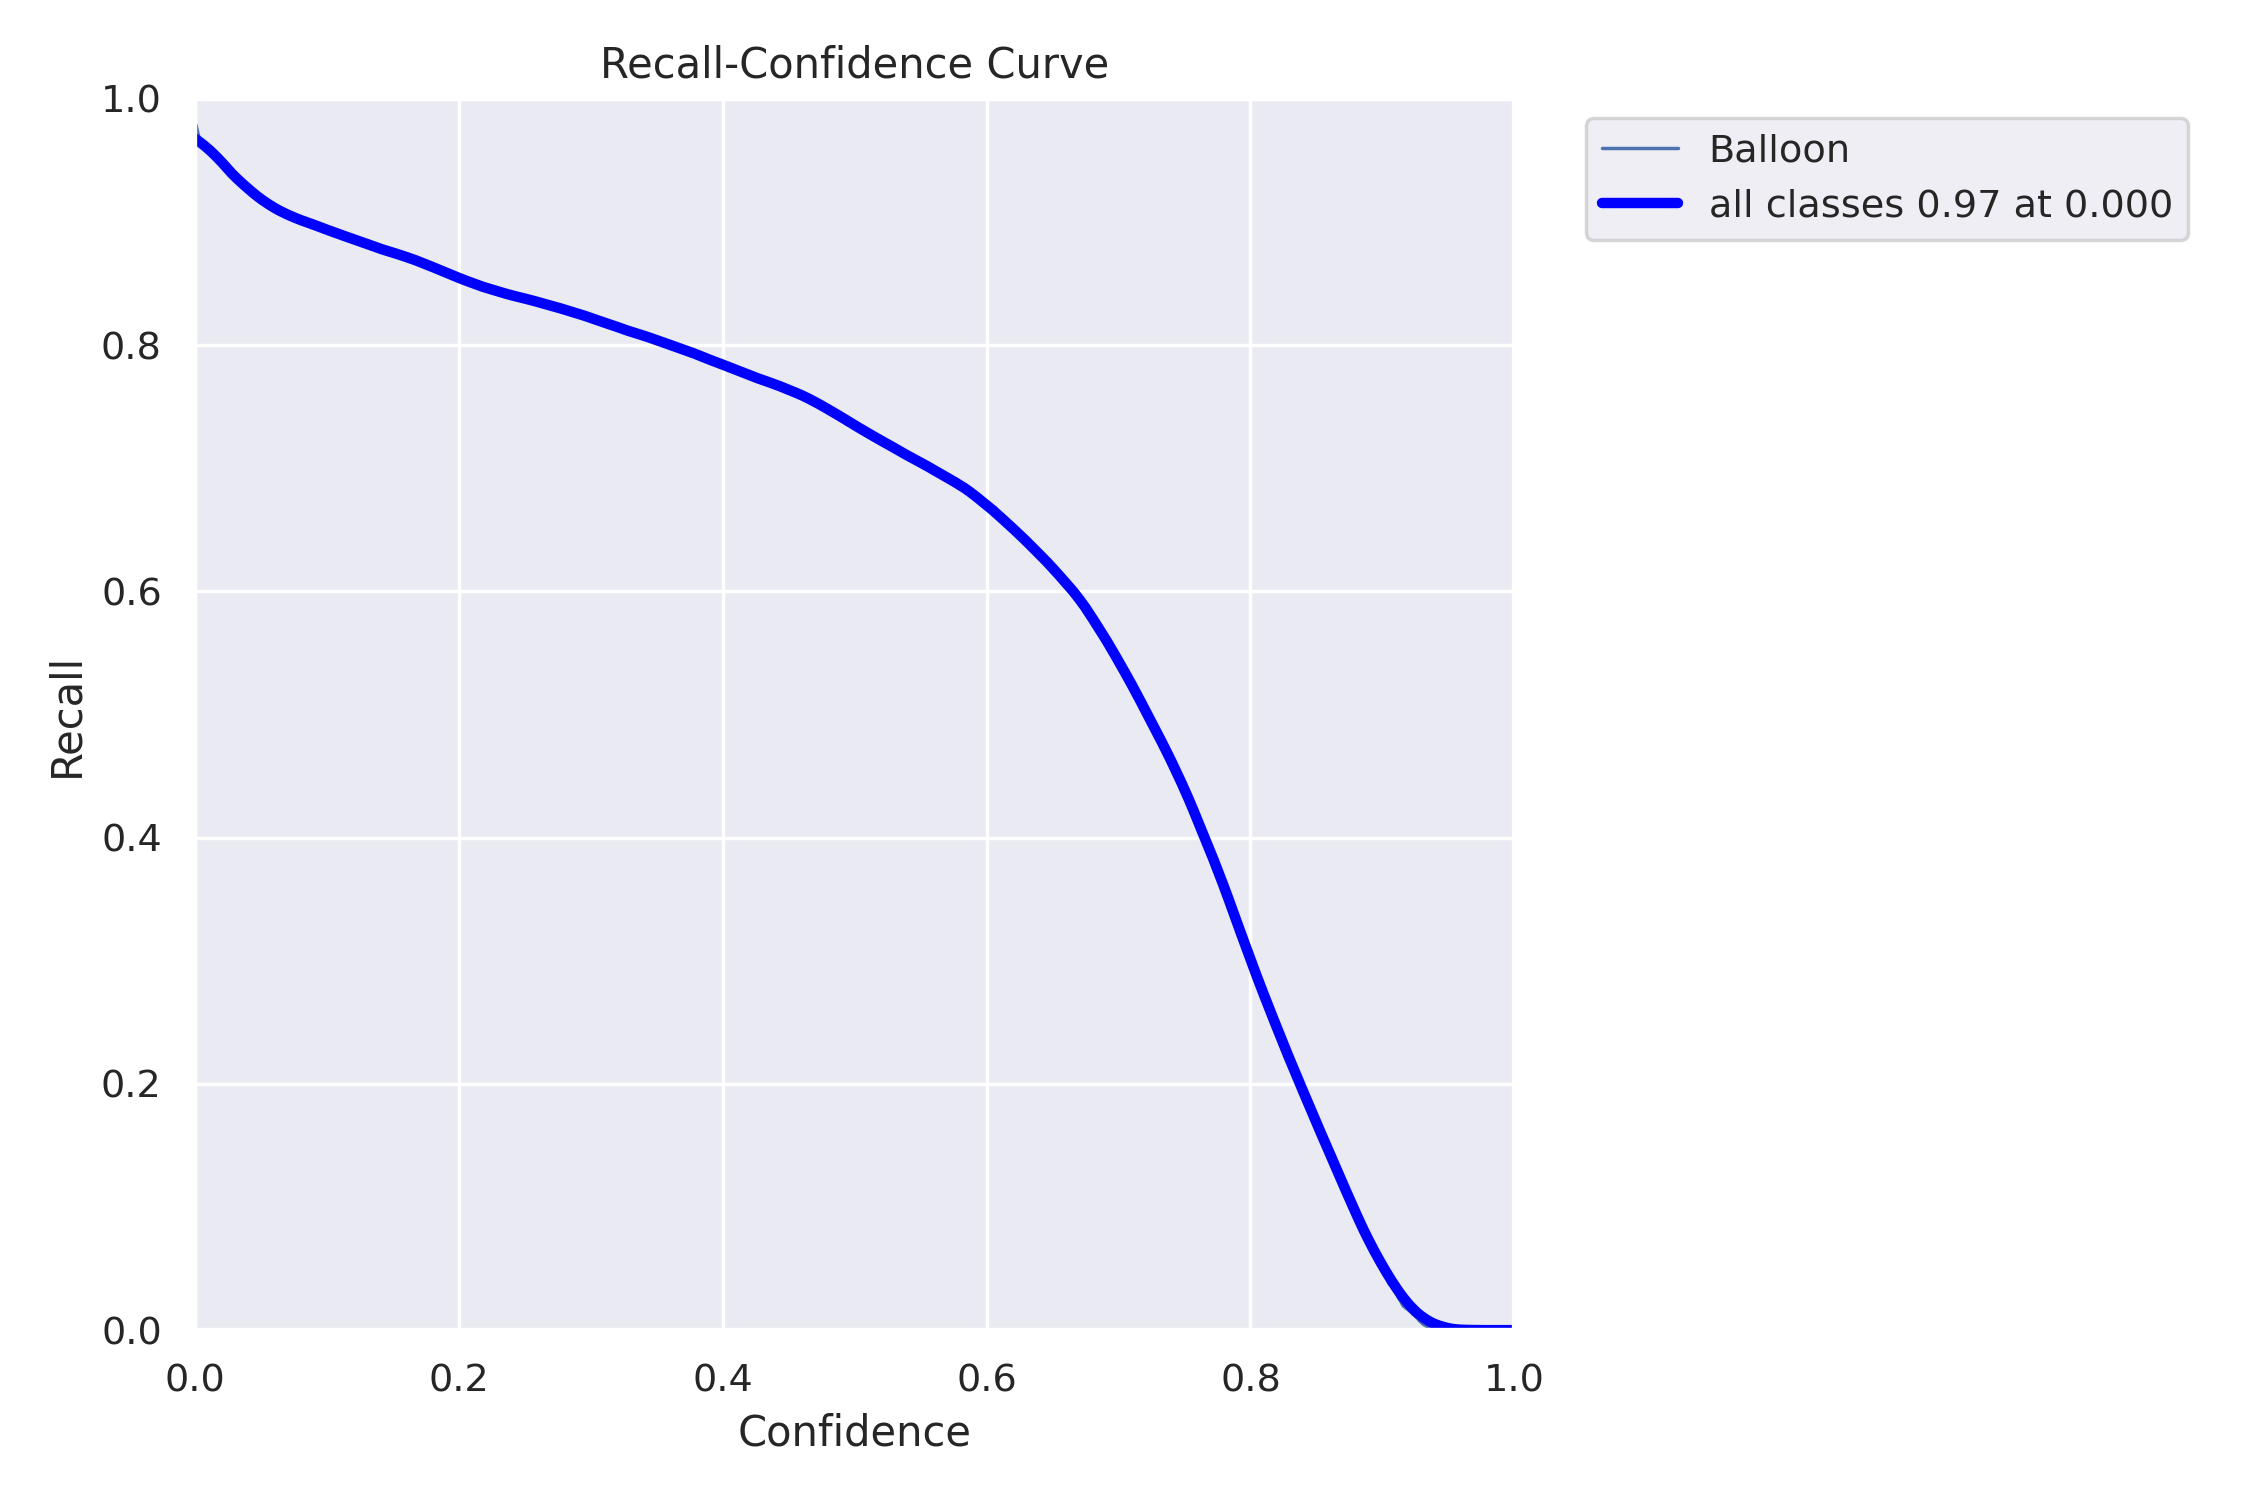

In [ ]:
Image(filename=f'/content/runs/detect/yolov8_ballon_tuning/R_curve.png', width=800)

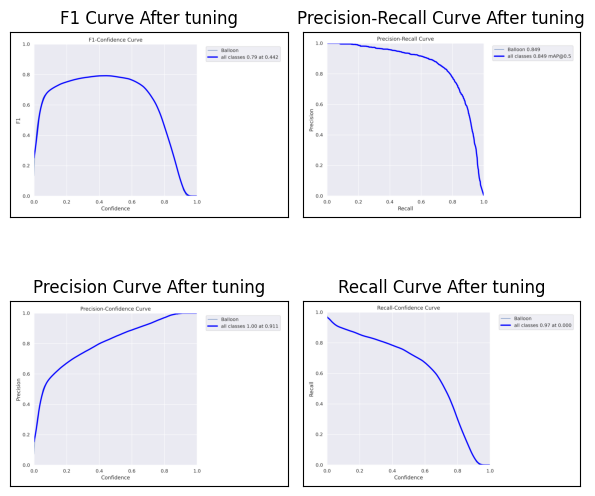

In [ ]:
image1 = plt.imread('/content/runs/detect/yolov8_ballon_tuning/F1_curve.png')
image2 = plt.imread('/content/runs/detect/yolov8_ballon_tuning/PR_curve.png')
image3 = plt.imread('/content/runs/detect/yolov8_ballon_tuning/P_curve.png')
image4 = plt.imread('/content/runs/detect/yolov8_ballon_tuning/R_curve.png')

fig, axs = plt.subplots(2, 2, figsize=(6, 6))

axs[0, 0].imshow(image1)
axs[0, 0].set_title('F1 Curve After tuning')

axs[0, 1].imshow(image2)
axs[0, 1].set_title('Precision-Recall Curve After tuning')

axs[1, 0].imshow(image3)
axs[1, 0].set_title('Precision Curve After tuning')
axs[1, 1].imshow(image4)
axs[1, 1].set_title('Recall Curve After tuning')

for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

#Validation

In [ ]:
!yolo detect val model=/content/runs/detect/yolov8_ballon_tuning/weights/best.pt data=/content/Blimp_Yolo_v8_Custom-1/data.yaml iou=0.5 name=yolov8-balloon-default-val

2024-05-13 18:30:56.130127: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-13 18:30:56.130180: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-13 18:30:56.131568: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-13 18:30:57.312937: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
Ultralytics YOLOv8.0.20 🚀 Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 268 layers, 43607379 parameters, 0 gradients, 164.8 GFLOPs
val: Scanning /content/Blimp_Yolo_v8_Custom-1/valid/labels.cache... 1413

#Test

In [ ]:
!yolo detect predict model=/content/runs/detect/yolov8_ballon_tuning/weights/best.pt conf=0.25 source=/content/Blimp_Yolo_v8_Custom-1/test/images save=True plots=True

2024-05-13 18:35:11.055241: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-13 18:35:11.055289: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-13 18:35:11.056570: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-13 18:35:12.100030: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
Ultralytics YOLOv8.0.20 🚀 Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 268 layers, 43607379 parameters, 0 gradients, 164.8 GFLOPs
image 1/696 /content/Blimp_Yolo_v8_Custom-1/test/images/-123-_png_jpg.rf

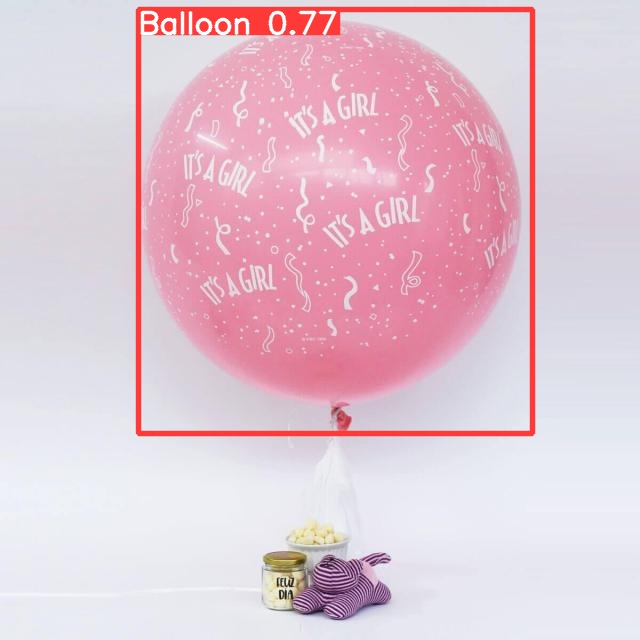

In [ ]:
image_p = '/content/runs/detect/predict/BALLON-21-_jpg.rf.5efdaa4de8220c8d56d6329c9fd83700.jpg'
display(Image(filename=image_p))

# Video streaming

In [ ]:
!yolo task=detect mode=predict model=/content/runs/detect/yolov8_ballon_tuning/weights/best.pt source='/content/balloons.mp4' save=True

2024-05-13 20:05:12.032217: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-13 20:05:12.032262: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-13 20:05:12.033490: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-13 20:05:14.303779: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
Ultralytics YOLOv8.0.20 🚀 Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 268 layers, 43607379 parameters, 0 gradients, 164.8 GFLOPs
video 1/1 (1/607) /content/balloons.mp4: 384x640 71.4ms
video 1/1 (2/607